In [7]:
import os
import pandas as pd
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

# ─── 1. GOOGLE COLAB SETUP ───────────────────────────────────────────────────
# Run this cell once to mount your drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Drive mounted successfully.")
except ImportError:
    print("Not running in Google Colab. Skipping drive mount.")

# ─── 2. CONFIGURATION ────────────────────────────────────────────────────────
# !!! UPDATE THESE PATHS to match your Google Drive structure !!!
CSV_PATH = "/content/drive/MyDrive/AUDIO DATASET FOR SPEECH THERPY/dataset/data_with_path.csv"
BASE_DIR = "/content/archive (11).zip"
OUTPUT_DIR = "LSTM_Model_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

EPOCHS = 20
BATCH_SIZE = 32
LEARNING_RATE = 0.001
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

# ─── 3. DATASET & MODEL ───────────────────────────────────────────────────────

class MFCCDataset(Dataset):
    def __init__(self, wav_paths, labels, target_sr=16000, duration=3, n_mfcc=40):
        self.wav_paths = wav_paths
        self.labels = labels
        self.target_sr = target_sr
        self.duration = duration
        self.samples = int(target_sr * duration)
        self.n_mfcc = n_mfcc

    def __len__(self): return len(self.wav_paths)

    def __getitem__(self, idx):
        wav_path = self.wav_paths[idx]
        label = self.labels[idx]
        try:
            audio, sr = librosa.load(wav_path, sr=self.target_sr)
            if len(audio) < self.samples:
                audio = np.pad(audio, (0, self.samples - len(audio)))
            else:
                audio = audio[:self.samples]
            mfccs = librosa.feature.mfcc(y=audio, sr=self.target_sr, n_mfcc=self.n_mfcc)
            mfccs = (mfccs - mfccs.mean()) / (mfccs.std() + 1e-9)
            return torch.tensor(mfccs, dtype=torch.float32), torch.tensor(label, dtype=torch.long)
        except:
            return torch.zeros((self.n_mfcc, 94)), torch.tensor(label, dtype=torch.long)

class AudioLSTM(nn.Module):
    def __init__(self, input_size=40, hidden_size=128, num_layers=2, num_classes=2, dropout=0.3):
        super(AudioLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0, bidirectional=True)
        self.attention = nn.Sequential(nn.Linear(hidden_size * 2, 64), nn.Tanh(), nn.Linear(64, 1))
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = x.transpose(1, 2)
        lstm_out, _ = self.lstm(x)
        weights = torch.softmax(self.attention(lstm_out), dim=1)
        context = torch.sum(weights * lstm_out, dim=1)
        return self.classifier(context)

# ─── 4. HELPERS ──────────────────────────────────────────────────────────────

def fix_path(path, base_dir):
    parts = path.split('/')
    try:
        idx = parts.index("Dysarthria and Non Dysarthria")
        return os.path.join(base_dir, *parts[idx:])
    except: return None

def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for samples, labels in loader:
            samples, labels = samples.to(DEVICE), labels.to(DEVICE)
            outputs = model(samples)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

# ─── 5. MAIN EXECUTION ───────────────────────────────────────────────────────

def main():
    if not os.path.exists(CSV_PATH):
        print(f"Error: CSV file not found at {CSV_PATH}. Check your Drive mount.")
        return

    df = pd.read_csv(CSV_PATH)
    label_map = {"No": 0, "Yes": 1}
    wav_paths, labels = [], []

    print("Preparing paths...")
    for i in range(len(df)):
        wp = fix_path(df.iloc[i]['Wav_path'], BASE_DIR)
        if wp and os.path.exists(wp):
            wav_paths.append(wp)
            labels.append(label_map[df.iloc[i]['Is_dysarthria']])

    print(f"Found {len(wav_paths)} files.")
    X_train, X_temp, y_train, y_temp = train_test_split(wav_paths, labels, test_size=0.2, random_state=42, stratify=labels)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

    train_loader = DataLoader(MFCCDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(MFCCDataset(X_val, y_val), batch_size=BATCH_SIZE)
    test_loader = DataLoader(MFCCDataset(X_test, y_test), batch_size=BATCH_SIZE)

    model = AudioLSTM().to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

    best_acc = 0
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")
        for samples, batch_y in pbar:
            samples, batch_y = samples.to(DEVICE), batch_y.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(samples)
            loss = criterion(outputs, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item()

        val_acc = evaluate(model, val_loader)
        print(f"Loss: {total_loss/len(train_loader):.4f} | Val Acc: {val_acc:.2f}%")

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, 'best_lstm.pth'))

    # Final Evaluation
    model.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, 'best_lstm.pth')))
    print(f"\nFinal Test Accuracy: {evaluate(model, test_loader):.2f}%")

if __name__ == "__main__":
    main()

MessageError: Error: credential propagation was unsuccessful

In [8]:
# ============================================================
# Dysarthria Detection using CNN — Google Colab
# Dataset: "Dysarthria and Non Dysarthria" (WAV audio files)
# Binary Classification: Dysarthric (1) vs Non-Dysarthric (0)
# Split: 80% Train | 10% Validation | 10% Test
# Epochs: 20
# ============================================================

# ─── STEP 0: Install dependencies ───────────────────────────
# Run this cell first in Colab
# !pip install librosa soundfile

# ─── STEP 1: Mount Google Drive & Extract Dataset ────────────
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os

# ── UPDATE THIS PATH to wherever you uploaded the zip in Drive ──
ZIP_PATH    = '/content/drive/MyDrive/archive__11_.zip'
EXTRACT_DIR = '/content/dysarthria_dataset'

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)
    print(f"Extracted to {EXTRACT_DIR}")

# ─── STEP 2: Imports ─────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from tqdm import tqdm
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, roc_curve, auc)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

# ─── STEP 3: Dataset Configuration ──────────────────────────
# Folder names that contain "dysarthria" but NOT "Non" → label 1
# Folder names that contain "Non" → label 0
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

# MFCC feature parameters
SAMPLE_RATE = 16000   # Resample all audio to 16 kHz
DURATION    = 3.0     # Clip / pad every file to 3 seconds
N_MFCC      = 40      # Number of MFCC coefficients
HOP_LENGTH  = 512
N_FFT       = 1024
# Output shape of each MFCC image: (N_MFCC, TIME_FRAMES, 1)
TIME_FRAMES = int(np.ceil(SAMPLE_RATE * DURATION / HOP_LENGTH))

# ─── STEP 4: Feature Extraction ─────────────────────────────
def extract_mfcc(file_path, sr=SAMPLE_RATE, duration=DURATION,
                 n_mfcc=N_MFCC, hop_length=HOP_LENGTH, n_fft=N_FFT):
    """Load WAV, normalise length, compute MFCC spectrogram."""
    try:
        y, _ = librosa.load(str(file_path), sr=sr, mono=True)
        # Fix length: pad with zeros or truncate
        target_len = int(sr * duration)
        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc,
                                     hop_length=hop_length, n_fft=n_fft)
        # Normalise per utterance
        mfcc = (mfcc - mfcc.mean()) / (mfcc.std() + 1e-9)
        return mfcc
    except Exception as e:
        print(f"  Error loading {file_path}: {e}")
        return None


def collect_files(root: Path, category_dirs: list, label: int):
    """Walk directory tree and collect all .wav files with a label."""
    records = []
    for cat_dir in category_dirs:
        cat_path = root / cat_dir
        if not cat_path.exists():
            print(f"  WARNING: {cat_path} not found – skipping.")
            continue
        for wav_file in cat_path.rglob('*.wav'):
            records.append({'path': wav_file, 'label': label})
    return records


print("Scanning dataset…")
dysarthric     = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS,     label=1)
non_dysarthric = collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, label=0)
all_records    = dysarthric + non_dysarthric

print(f"Dysarthric files    : {len(dysarthric)}")
print(f"Non-Dysarthric files: {len(non_dysarthric)}")
print(f"Total files         : {len(all_records)}")

# ── Extract MFCCs ────────────────────────────────────────────
features, labels = [], []

print("\nExtracting MFCCs …")
for rec in tqdm(all_records):
    mfcc = extract_mfcc(rec['path'])
    if mfcc is not None:
        features.append(mfcc)
        labels.append(rec['label'])

features = np.array(features)  # shape: (N, N_MFCC, TIME_FRAMES)
labels   = np.array(labels)

# Add channel dimension for CNN: (N, N_MFCC, TIME_FRAMES, 1)
features = features[..., np.newaxis]

print(f"\nFeature array shape : {features.shape}")
print(f"Label distribution  : {Counter(labels)}")

# ─── STEP 5: Train / Val / Test Split (80 / 10 / 10) ────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    features, labels, test_size=0.10, random_state=42, stratify=labels)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.1111,           # 0.1 / 0.9 ≈ 11.11% of train_val → 10% of total
    random_state=42, stratify=y_train_val)

print(f"\nTrain samples : {len(X_train)}  (Dysarthric={y_train.sum()}, Non={len(y_train)-y_train.sum()})")
print(f"Val   samples : {len(X_val)}   (Dysarthric={y_val.sum()}, Non={len(y_val)-y_val.sum()})")
print(f"Test  samples : {len(X_test)}   (Dysarthric={y_test.sum()}, Non={len(y_test)-y_test.sum()})")

# ─── STEP 6: CNN Model ───────────────────────────────────────
INPUT_SHAPE = features.shape[1:]   # (N_MFCC, TIME_FRAMES, 1)
NUM_CLASSES = 2

def build_cnn(input_shape, num_classes):
    """
    3-block CNN for spectrogram-based speech classification.
    Block: Conv2D → BN → ReLU → MaxPool → Dropout
    Head : GlobalAveragePool → Dense → Softmax
    """
    inp = keras.Input(shape=input_shape, name='mfcc_input')

    # Block 1
    x = layers.Conv2D(32, (3, 3), padding='same', name='conv1')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Block 2
    x = layers.Conv2D(64, (3, 3), padding='same', name='conv2')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Block 3
    x = layers.Conv2D(128, (3, 3), padding='same', name='conv3')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.30)(x)

    # Classifier head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.40)(x)
    out = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = keras.Model(inputs=inp, outputs=out, name='DysarthraCNN')
    return model


model = build_cnn(INPUT_SHAPE, NUM_CLASSES)
model.summary()

# ─── STEP 7: Compile & Train ────────────────────────────────
EPOCHS     = 20
BATCH_SIZE = 32
LR         = 1e-3

# Class weights to handle imbalance
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = {0: cw[0], 1: cw[1]}
print(f"\nClass weights: {class_weights}")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks
cb_early_stop  = callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                          restore_best_weights=True, verbose=1)
cb_reduce_lr   = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                               patience=3, min_lr=1e-6, verbose=1)
cb_checkpoint  = callbacks.ModelCheckpoint('best_dysarthria_cnn.keras',
                                            monitor='val_accuracy',
                                            save_best_only=True, verbose=1)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[cb_early_stop, cb_reduce_lr, cb_checkpoint],
    verbose=1
)

# ─── STEP 8: Evaluate on Test Set ───────────────────────────
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\n{'='*50}")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc*100:.2f}%")
print(f"{'='*50}")

y_pred_proba = model.predict(X_test)
y_pred       = np.argmax(y_pred_proba, axis=1)
class_names  = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: ALL GRAPHS ─────────────────────────────────────

# ── 9.1  Training & Validation Accuracy Curve ─────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('CNN Training History', fontsize=16, fontweight='bold')

ep = range(1, len(history.history['accuracy']) + 1)

axes[0].plot(ep, history.history['accuracy'],     'b-o', linewidth=2,
             markersize=5, label='Train Accuracy')
axes[0].plot(ep, history.history['val_accuracy'], 'r-o', linewidth=2,
             markersize=5, label='Val Accuracy')
axes[0].set_title('Accuracy Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# ── 9.2  Training & Validation Loss Curve ─────────────────────
axes[1].plot(ep, history.history['loss'],     'b-o', linewidth=2,
             markersize=5, label='Train Loss')
axes[1].plot(ep, history.history['val_loss'], 'r-o', linewidth=2,
             markersize=5, label='Val Loss')
axes[1].set_title('Loss Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: training_curves.png")

# ── 9.3  Confusion Matrix ─────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, annot_kws={'size': 14})
ax.set_title('Confusion Matrix (Test Set)', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: confusion_matrix.png")

# ── 9.4  ROC Curve ────────────────────────────────────────────
fpr, tpr, _ = roc_curve(y_test, y_pred_proba[:, 1])
roc_auc     = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2,
        label=f'ROC Curve (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--',
        label='Random Classifier')
ax.fill_between(fpr, tpr, alpha=0.15, color='darkorange')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve – Dysarthria Detection', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: roc_curve.png")

# ── 9.5  Per-Class Metrics Bar Chart ──────────────────────────
from sklearn.metrics import precision_score, recall_score, f1_score

report_dict = classification_report(y_test, y_pred,
                                     target_names=class_names,
                                     output_dict=True)
metrics_df = pd.DataFrame({
    'Precision': [report_dict[c]['precision'] for c in class_names],
    'Recall'   : [report_dict[c]['recall']    for c in class_names],
    'F1-Score' : [report_dict[c]['f1-score']  for c in class_names],
}, index=class_names)

metrics_df.plot(kind='bar', figsize=(8, 5), colormap='Set2', edgecolor='black',
                rot=0)
plt.title('Per-Class Metrics (Test Set)', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1.15)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.2f', fontsize=9)
plt.tight_layout()
plt.savefig('per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: per_class_metrics.png")

# ── 9.6  Accuracy Table (per epoch) ───────────────────────────
n_epochs_trained = len(history.history['accuracy'])
acc_table = pd.DataFrame({
    'Epoch'        : list(range(1, n_epochs_trained + 1)),
    'Train Acc (%)'     : [f"{v*100:.2f}" for v in history.history['accuracy']],
    'Val Acc (%)'       : [f"{v*100:.2f}" for v in history.history['val_accuracy']],
    'Train Loss'        : [f"{v:.4f}"     for v in history.history['loss']],
    'Val Loss'          : [f"{v:.4f}"     for v in history.history['val_loss']],
})
print("\n── Accuracy Table (per epoch) ──────────────────────────")
print(acc_table.to_string(index=False))

# Visualise as a styled table plot
fig, ax = plt.subplots(figsize=(12, min(2 + n_epochs_trained * 0.35, 9)))
ax.axis('off')
table = ax.table(
    cellText   = acc_table.values,
    colLabels  = acc_table.columns,
    cellLoc    = 'center',
    loc        = 'center',
    bbox       = [0, 0, 1, 1]
)
table.auto_set_font_size(False)
table.set_fontsize(9)
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor('#4C72B0')
        cell.set_text_props(color='white', fontweight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#f0f4fa')
plt.title('Epoch-wise Accuracy & Loss', fontsize=13,
          fontweight='bold', pad=14, y=1.01)
plt.tight_layout()
plt.savefig('accuracy_table.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: accuracy_table.png")

# ── 9.7  Dataset Distribution ─────────────────────────────────
label_counts = Counter(labels)
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(class_names, [label_counts[0], label_counts[1]],
              color=['#2196F3', '#FF5722'], edgecolor='black', width=0.5)
ax.bar_label(bars, fontsize=12)
ax.set_title('Dataset Class Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Samples')
ax.set_ylim(0, max(label_counts.values()) * 1.2)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: class_distribution.png")

# ── 9.8  Sample MFCC Spectrogram ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, (label, title) in enumerate(zip([0, 1], class_names)):
    idx = np.where(y_train == label)[0][0]
    mfcc_display = X_train[idx, :, :, 0]
    librosa.display.specshow(mfcc_display, sr=SAMPLE_RATE,
                             hop_length=HOP_LENGTH, x_axis='time',
                             ax=axes[i], cmap='magma')
    axes[i].set_title(f'MFCC – {title}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel('MFCC Coefficient')

fig.suptitle('Sample MFCC Spectrograms', fontsize=14, fontweight='bold')
plt.colorbar(axes[1].images[0], ax=axes, orientation='vertical',
             label='Magnitude')
plt.tight_layout()
plt.savefig('sample_mfcc.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sample_mfcc.png")

# ─── STEP 10: Final Summary ──────────────────────────────────
print("\n" + "="*60)
print("         FINAL EVALUATION SUMMARY")
print("="*60)
print(f"  Total Samples  : {len(labels)}")
print(f"  Train / Val / Test : {len(X_train)} / {len(X_val)} / {len(X_test)}")
print(f"  Epochs Trained : {n_epochs_trained}/{EPOCHS}")
print(f"  Test Accuracy  : {test_acc*100:.2f}%")
print(f"  Test Loss      : {test_loss:.4f}")
print(f"  ROC-AUC        : {roc_auc:.4f}")
print("="*60)
print("\nDetailed Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))
print("="*60)
print("\nAll graphs saved:")
saved = ['training_curves.png', 'confusion_matrix.png', 'roc_curve.png',
         'per_class_metrics.png', 'accuracy_table.png',
         'class_distribution.png', 'sample_mfcc.png']
for f in saved:
    print(f"  ✓ {f}")

MessageError: Error: credential propagation was unsuccessful

In [9]:
# ============================================================
# Dysarthria Detection using CNN — Google Colab
# Dataset: "Dysarthria and Non Dysarthria" (WAV audio files)
# Binary Classification: Dysarthric (1) vs Non-Dysarthric (0)
# Split: 80% Train | 10% Validation | 10% Test
# Epochs: 20
# ============================================================

# ─── STEP 0: Install dependencies ───────────────────────────
# Run this cell first in Colab
# !pip install librosa soundfile

# ─── STEP 1: Extract Dataset ─────────────────────────────────
# The zip file was uploaded directly to Colab session storage
# (Files panel → Upload → archive__11_.zip)
# It lands at /content/archive__11_.zip automatically.

import zipfile, os

ZIP_PATH    = '/content/archive__11_.zip'   # ← direct Colab upload path
EXTRACT_DIR = '/content/dysarthria_dataset'

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)
    print(f"Extracted to {EXTRACT_DIR}")

# ─── STEP 2: Imports ─────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from tqdm import tqdm
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, roc_curve, auc)

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

# ─── STEP 3: Dataset Configuration ──────────────────────────
# Folder names that contain "dysarthria" but NOT "Non" → label 1
# Folder names that contain "Non" → label 0
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

# MFCC feature parameters
SAMPLE_RATE = 16000   # Resample all audio to 16 kHz
DURATION    = 3.0     # Clip / pad every file to 3 seconds
N_MFCC      = 40      # Number of MFCC coefficients
HOP_LENGTH  = 512
N_FFT       = 1024
# Output shape of each MFCC image: (N_MFCC, TIME_FRAMES, 1)
TIME_FRAMES = int(np.ceil(SAMPLE_RATE * DURATION / HOP_LENGTH))

# ─── STEP 4: Feature Extraction ─────────────────────────────
def extract_mfcc(file_path, sr=SAMPLE_RATE, duration=DURATION,
                 n_mfcc=N_MFCC, hop_length=HOP_LENGTH, n_fft=N_FFT):
    """Load WAV, normalise length, compute MFCC spectrogram."""
    try:
        y, _ = librosa.load(str(file_path), sr=sr, mono=True)
        # Fix length: pad with zeros or truncate
        target_len = int(sr * duration)
        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc,
                                     hop_length=hop_length, n_fft=n_fft)
        # Normalise per utterance
        mfcc = (mfcc - mfcc.mean()) / (mfcc.std() + 1e-9)
        return mfcc
    except Exception as e:
        print(f"  Error loading {file_path}: {e}")
        return None


def collect_files(root: Path, category_dirs: list, label: int):
    """Walk directory tree and collect all .wav files with a label."""
    records = []
    for cat_dir in category_dirs:
        cat_path = root / cat_dir
        if not cat_path.exists():
            print(f"  WARNING: {cat_path} not found – skipping.")
            continue
        for wav_file in cat_path.rglob('*.wav'):
            records.append({'path': wav_file, 'label': label})
    return records


print("Scanning dataset…")
dysarthric     = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS,     label=1)
non_dysarthric = collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, label=0)
all_records    = dysarthric + non_dysarthric

print(f"Dysarthric files    : {len(dysarthric)}")
print(f"Non-Dysarthric files: {len(non_dysarthric)}")
print(f"Total files         : {len(all_records)}")

# ── Extract MFCCs ────────────────────────────────────────────
features, labels = [], []

print("\nExtracting MFCCs …")
for rec in tqdm(all_records):
    mfcc = extract_mfcc(rec['path'])
    if mfcc is not None:
        features.append(mfcc)
        labels.append(rec['label'])

features = np.array(features)  # shape: (N, N_MFCC, TIME_FRAMES)
labels   = np.array(labels)

# Add channel dimension for CNN: (N, N_MFCC, TIME_FRAMES, 1)
features = features[..., np.newaxis]

print(f"\nFeature array shape : {features.shape}")
print(f"Label distribution  : {Counter(labels)}")

# ─── STEP 5: Train / Val / Test Split (80 / 10 / 10) ────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    features, labels, test_size=0.10, random_state=42, stratify=labels)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.1111,           # 0.1 / 0.9 ≈ 11.11% of train_val → 10% of total
    random_state=42, stratify=y_train_val)

print(f"\nTrain samples : {len(X_train)}  (Dysarthric={y_train.sum()}, Non={len(y_train)-y_train.sum()})")
print(f"Val   samples : {len(X_val)}   (Dysarthric={y_val.sum()}, Non={len(y_val)-y_val.sum()})")
print(f"Test  samples : {len(X_test)}   (Dysarthric={y_test.sum()}, Non={len(y_test)-y_test.sum()})")

# ─── STEP 6: CNN Model ───────────────────────────────────────
INPUT_SHAPE = features.shape[1:]   # (N_MFCC, TIME_FRAMES, 1)
NUM_CLASSES = 2

def build_cnn(input_shape, num_classes):
    """
    3-block CNN for spectrogram-based speech classification.
    Block: Conv2D → BN → ReLU → MaxPool → Dropout
    Head : GlobalAveragePool → Dense → Softmax
    """
    inp = keras.Input(shape=input_shape, name='mfcc_input')

    # Block 1
    x = layers.Conv2D(32, (3, 3), padding='same', name='conv1')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Block 2
    x = layers.Conv2D(64, (3, 3), padding='same', name='conv2')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Block 3
    x = layers.Conv2D(128, (3, 3), padding='same', name='conv3')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.30)(x)

    # Classifier head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.40)(x)
    out = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = keras.Model(inputs=inp, outputs=out, name='DysarthraCNN')
    return model


model = build_cnn(INPUT_SHAPE, NUM_CLASSES)
model.summary()

# ─── STEP 7: Compile & Train ────────────────────────────────
EPOCHS     = 20
BATCH_SIZE = 32
LR         = 1e-3

# Class weights to handle imbalance
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = {0: cw[0], 1: cw[1]}
print(f"\nClass weights: {class_weights}")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks
cb_early_stop  = callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                          restore_best_weights=True, verbose=1)
cb_reduce_lr   = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                               patience=3, min_lr=1e-6, verbose=1)
cb_checkpoint  = callbacks.ModelCheckpoint('best_dysarthria_cnn.keras',
                                            monitor='val_accuracy',
                                            save_best_only=True, verbose=1)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[cb_early_stop, cb_reduce_lr, cb_checkpoint],
    verbose=1
)

# ─── STEP 8: Evaluate on Test Set ───────────────────────────
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\n{'='*50}")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc*100:.2f}%")
print(f"{'='*50}")

y_pred_proba = model.predict(X_test)
y_pred       = np.argmax(y_pred_proba, axis=1)
class_names  = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: ALL GRAPHS ─────────────────────────────────────

# ── 9.1  Training & Validation Accuracy Curve ─────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('CNN Training History', fontsize=16, fontweight='bold')

ep = range(1, len(history.history['accuracy']) + 1)

axes[0].plot(ep, history.history['accuracy'],     'b-o', linewidth=2,
             markersize=5, label='Train Accuracy')
axes[0].plot(ep, history.history['val_accuracy'], 'r-o', linewidth=2,
             markersize=5, label='Val Accuracy')
axes[0].set_title('Accuracy Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# ── 9.2  Training & Validation Loss Curve ─────────────────────
axes[1].plot(ep, history.history['loss'],     'b-o', linewidth=2,
             markersize=5, label='Train Loss')
axes[1].plot(ep, history.history['val_loss'], 'r-o', linewidth=2,
             markersize=5, label='Val Loss')
axes[1].set_title('Loss Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: training_curves.png")

# ── 9.3  Confusion Matrix ─────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, annot_kws={'size': 14})
ax.set_title('Confusion Matrix (Test Set)', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: confusion_matrix.png")

# ── 9.4  ROC Curve ────────────────────────────────────────────
fpr, tpr, _ = roc_curve(y_test, y_pred_proba[:, 1])
roc_auc     = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2,
        label=f'ROC Curve (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--',
        label='Random Classifier')
ax.fill_between(fpr, tpr, alpha=0.15, color='darkorange')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve – Dysarthria Detection', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: roc_curve.png")

# ── 9.5  Per-Class Metrics Bar Chart ──────────────────────────
from sklearn.metrics import precision_score, recall_score, f1_score

report_dict = classification_report(y_test, y_pred,
                                     target_names=class_names,
                                     output_dict=True)
metrics_df = pd.DataFrame({
    'Precision': [report_dict[c]['precision'] for c in class_names],
    'Recall'   : [report_dict[c]['recall']    for c in class_names],
    'F1-Score' : [report_dict[c]['f1-score']  for c in class_names],
}, index=class_names)

metrics_df.plot(kind='bar', figsize=(8, 5), colormap='Set2', edgecolor='black',
                rot=0)
plt.title('Per-Class Metrics (Test Set)', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1.15)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='%.2f', fontsize=9)
plt.tight_layout()
plt.savefig('per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: per_class_metrics.png")

# ── 9.6  Accuracy Table (per epoch) ───────────────────────────
n_epochs_trained = len(history.history['accuracy'])
acc_table = pd.DataFrame({
    'Epoch'        : list(range(1, n_epochs_trained + 1)),
    'Train Acc (%)'     : [f"{v*100:.2f}" for v in history.history['accuracy']],
    'Val Acc (%)'       : [f"{v*100:.2f}" for v in history.history['val_accuracy']],
    'Train Loss'        : [f"{v:.4f}"     for v in history.history['loss']],
    'Val Loss'          : [f"{v:.4f}"     for v in history.history['val_loss']],
})
print("\n── Accuracy Table (per epoch) ──────────────────────────")
print(acc_table.to_string(index=False))

# Visualise as a styled table plot
fig, ax = plt.subplots(figsize=(12, min(2 + n_epochs_trained * 0.35, 9)))
ax.axis('off')
table = ax.table(
    cellText   = acc_table.values,
    colLabels  = acc_table.columns,
    cellLoc    = 'center',
    loc        = 'center',
    bbox       = [0, 0, 1, 1]
)
table.auto_set_font_size(False)
table.set_fontsize(9)
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor('#4C72B0')
        cell.set_text_props(color='white', fontweight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#f0f4fa')
plt.title('Epoch-wise Accuracy & Loss', fontsize=13,
          fontweight='bold', pad=14, y=1.01)
plt.tight_layout()
plt.savefig('accuracy_table.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: accuracy_table.png")

# ── 9.7  Dataset Distribution ─────────────────────────────────
label_counts = Counter(labels)
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(class_names, [label_counts[0], label_counts[1]],
              color=['#2196F3', '#FF5722'], edgecolor='black', width=0.5)
ax.bar_label(bars, fontsize=12)
ax.set_title('Dataset Class Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Samples')
ax.set_ylim(0, max(label_counts.values()) * 1.2)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: class_distribution.png")

# ── 9.8  Sample MFCC Spectrogram ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, (label, title) in enumerate(zip([0, 1], class_names)):
    idx = np.where(y_train == label)[0][0]
    mfcc_display = X_train[idx, :, :, 0]
    librosa.display.specshow(mfcc_display, sr=SAMPLE_RATE,
                             hop_length=HOP_LENGTH, x_axis='time',
                             ax=axes[i], cmap='magma')
    axes[i].set_title(f'MFCC – {title}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel('MFCC Coefficient')

fig.suptitle('Sample MFCC Spectrograms', fontsize=14, fontweight='bold')
plt.colorbar(axes[1].images[0], ax=axes, orientation='vertical',
             label='Magnitude')
plt.tight_layout()
plt.savefig('sample_mfcc.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sample_mfcc.png")

# ─── STEP 10: Final Summary ──────────────────────────────────
print("\n" + "="*60)
print("         FINAL EVALUATION SUMMARY")
print("="*60)
print(f"  Total Samples  : {len(labels)}")
print(f"  Train / Val / Test : {len(X_train)} / {len(X_val)} / {len(X_test)}")
print(f"  Epochs Trained : {n_epochs_trained}/{EPOCHS}")
print(f"  Test Accuracy  : {test_acc*100:.2f}%")
print(f"  Test Loss      : {test_loss:.4f}")
print(f"  ROC-AUC        : {roc_auc:.4f}")
print("="*60)
print("\nDetailed Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))
print("="*60)
print("\nAll graphs saved:")
saved = ['training_curves.png', 'confusion_matrix.png', 'roc_curve.png',
         'per_class_metrics.png', 'accuracy_table.png',
         'class_distribution.png', 'sample_mfcc.png']
for f in saved:
    print(f"  ✓ {f}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/archive__11_.zip'

ZIP files found in /content:
  /content/archive (11).zip

Using zip : /content/archive (11).zip
Extracted  : /content/dysarthria_dataset

Top-level contents after extraction:
  Dysarthria and Non Dysarthria
  data_with_path.csv
TensorFlow: 2.20.0
GPU available: []
Scanning dataset…
Dysarthric files    : 1363
Non-Dysarthric files: 2953
Total files         : 4316

Extracting MFCCs …


  0%|          | 12/4316 [00:20<59:35,  1.20it/s] 

  Error loading /content/dysarthria_dataset/Dysarthria and Non Dysarthria/Dataset/Female_dysarthria/F01/Session1/Wav/0067.wav: 


  1%|          | 42/4316 [00:21<05:50, 12.21it/s]

  Error loading /content/dysarthria_dataset/Dysarthria and Non Dysarthria/Dataset/Female_dysarthria/F01/Session1/Wav/0068.wav: 


100%|██████████| 4316/4316 [01:08<00:00, 63.41it/s] 


... (3 outputs left out)

 Total params: 110,338 (431.01 KB)

 Trainable params: 109,890 (429.26 KB)

 Non-trainable params: 448 (1.75 KB)

Class weights: {0: np.float64(0.7306226175349428), 1: np.float64(1.584022038567493)}
Epoch 1/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.5838 - loss: 0.6847
Epoch 1: val_accuracy improved from None to 0.49537, saving model to best_dysarthria_cnn.keras

Epoch 1: finished saving model to best_dysarthria_cnn.keras
108/108 ━━━━━━━━━━━━━━━━━━━━ 49s 410ms/step - accuracy: 0.6386 - loss: 0.6262 - val_accuracy: 0.4954 - val_loss: 0.6901 - learning_rate: 0.0010
Epoch 2/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step - accuracy: 0.7239 - loss: 0.5199
Epoch 2: val_accuracy improved from 0.49537 to 0.75694, saving model to best_dysarthria_cnn.keras

Epoch 2: finished saving model to best_dysarthria_cnn.keras
108/108 ━━━━━━━━━━━━━━━━━━━━ 80s 397ms/step - accuracy: 0.7548 - loss: 0.4914 - val_accuracy: 0.7569 - val_loss: 0.6197 - learning_rate: 0.0010
Epoch 3/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.7874 - loss: 0.4434
Epoch 3: val_accuracy did not improve from 0.756

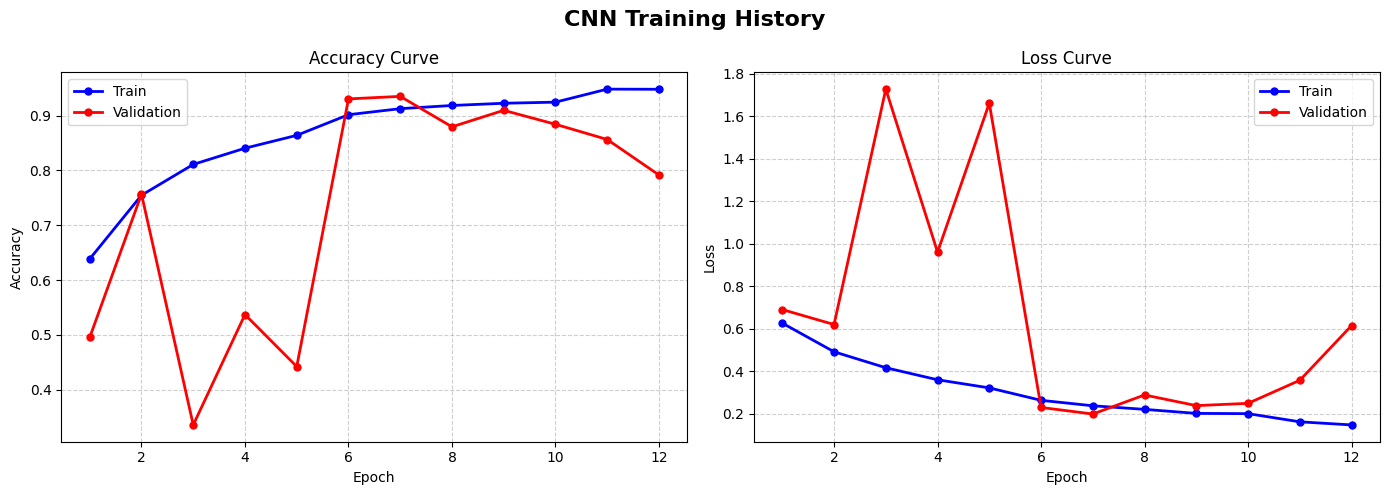

Saved: training_curves.png


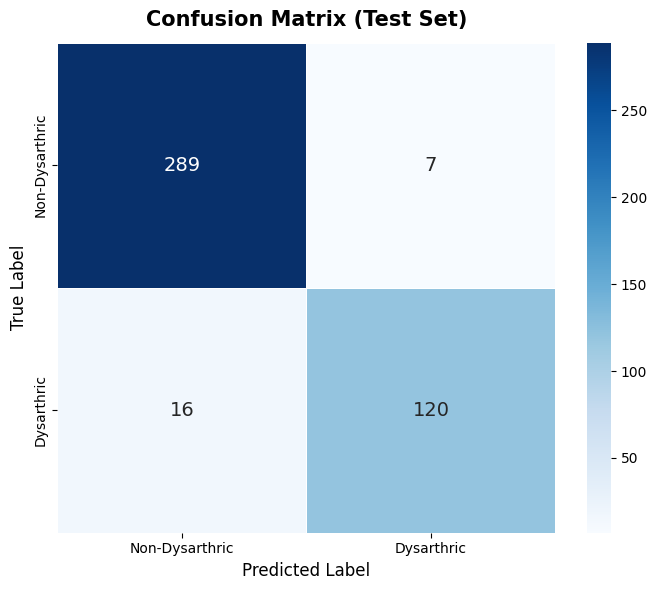

Saved: confusion_matrix.png


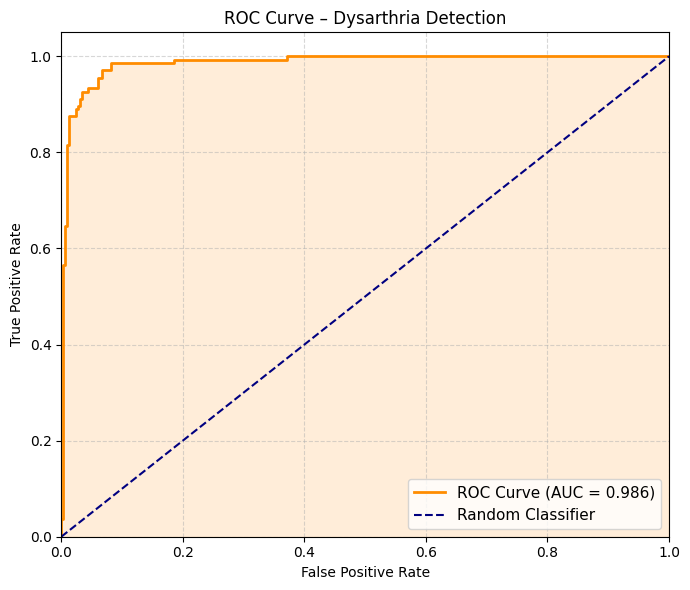

Saved: roc_curve.png


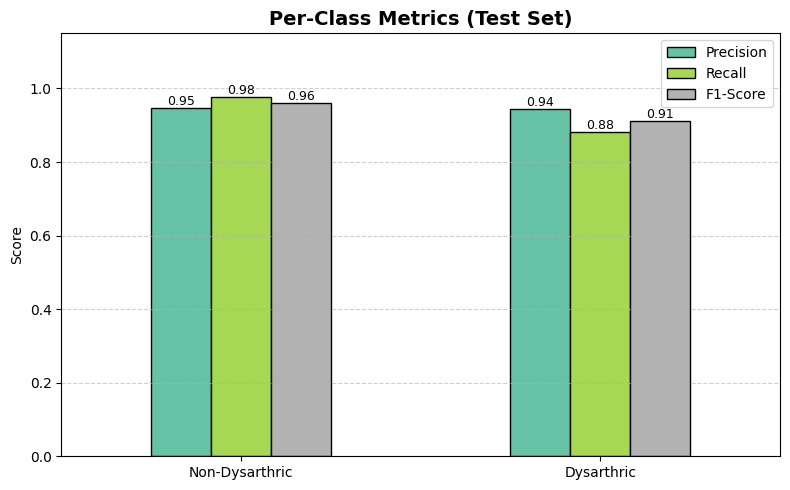

Saved: per_class_metrics.png

── Accuracy Table ──────────────────────────────────────
 Epoch Train Acc (%) Val Acc (%) Train Loss Val Loss
     1         63.86       49.54     0.6262   0.6901
     2         75.48       75.69     0.4914   0.6197
     3         81.10       33.56     0.4164   1.7275
     4         84.06       53.70     0.3597   0.9606
     5         86.41       44.21     0.3215   1.6614
     6         90.17       93.06     0.2630   0.2294
     7         91.28       93.52     0.2373   0.1985
     8         91.86       87.96     0.2204   0.2882
     9         92.26       90.97     0.2015   0.2381
    10         92.46       88.43     0.2003   0.2487
    11         94.84       85.65     0.1619   0.3572
    12         94.81       79.17     0.1472   0.6146


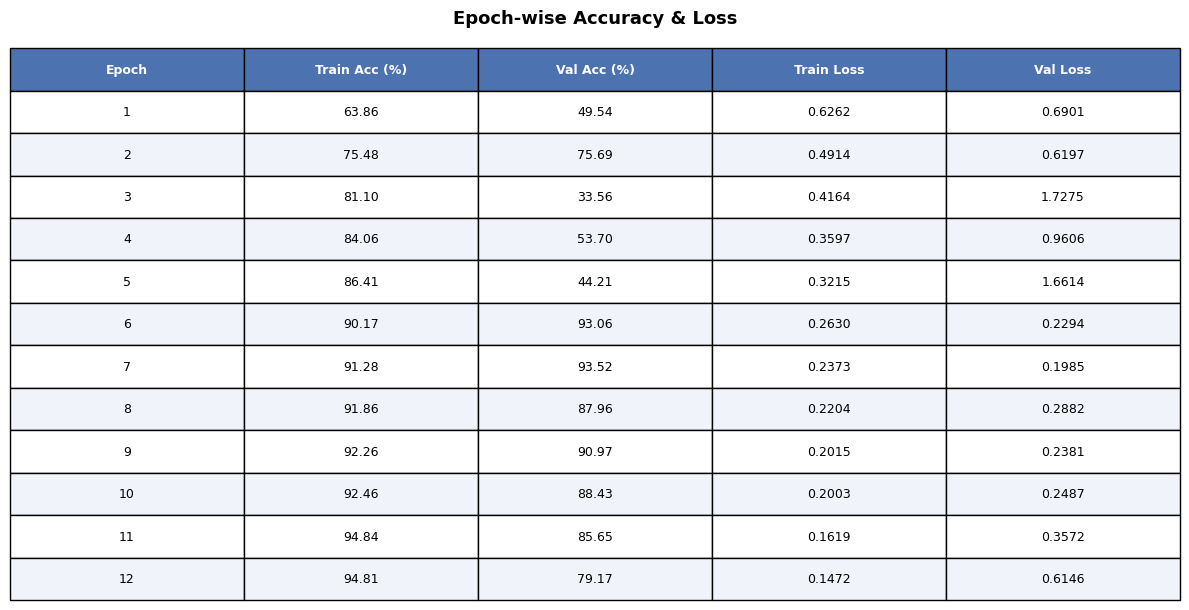

Saved: accuracy_table.png


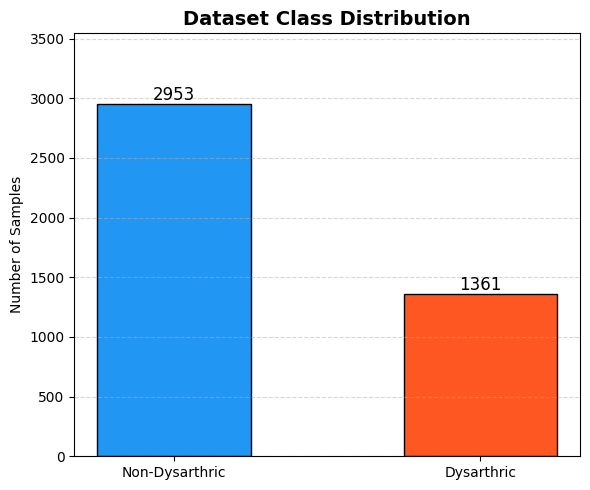

Saved: class_distribution.png


IndexError: list index out of range

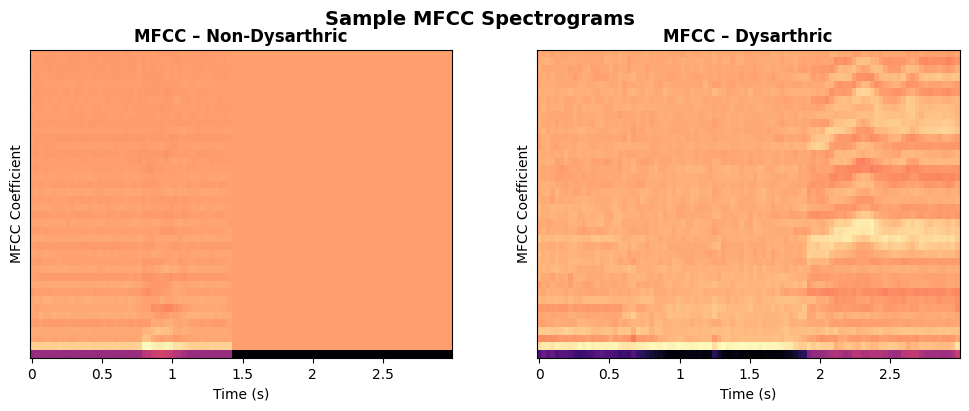

In [10]:
# ============================================================
# Dysarthria Detection using CNN — Google Colab
# Dataset: "Dysarthria and Non Dysarthria" (WAV audio files)
# Binary Classification: Dysarthric (1) vs Non-Dysarthric (0)
# Split: 80% Train | 10% Validation | 10% Test
# Epochs: 20
# ============================================================

# ─── STEP 0: Install dependencies ───────────────────────────
# !pip install librosa soundfile tqdm

# ─── STEP 1: Find & Extract Dataset ─────────────────────────
import zipfile, os, glob

# Auto-detect the uploaded zip anywhere under /content
zip_matches = glob.glob('/content/**/*.zip', recursive=True) + \
              glob.glob('/content/*.zip')

# Remove duplicates while preserving order
seen = set()
zip_matches = [p for p in zip_matches if not (p in seen or seen.add(p))]

print("ZIP files found in /content:")
for p in zip_matches:
    print(f"  {p}")

if not zip_matches:
    raise FileNotFoundError(
        "\nNo .zip found under /content.\n"
        "Please upload the zip via the Files panel:\n"
        "  Left sidebar → folder icon → Upload icon → select your zip file."
    )

ZIP_PATH    = zip_matches[0]
EXTRACT_DIR = '/content/dysarthria_dataset'

print(f"\nUsing zip : {ZIP_PATH}")
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)
    print(f"Extracted  : {EXTRACT_DIR}")

# Verify structure
print("\nTop-level contents after extraction:")
for entry in sorted(os.listdir(EXTRACT_DIR)):
    print(f"  {entry}")

# ─── STEP 2: Imports ─────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from tqdm import tqdm
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, roc_curve, auc)
from sklearn.utils.class_weight import compute_class_weight

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

# ─── STEP 3: Dataset Configuration ──────────────────────────
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

SAMPLE_RATE  = 16000
DURATION     = 3.0
N_MFCC       = 40
HOP_LENGTH   = 512
N_FFT        = 1024
TIME_FRAMES  = int(np.ceil(SAMPLE_RATE * DURATION / HOP_LENGTH))

# ─── STEP 4: Feature Extraction ──────────────────────────────
def extract_mfcc(file_path, sr=SAMPLE_RATE, duration=DURATION,
                 n_mfcc=N_MFCC, hop_length=HOP_LENGTH, n_fft=N_FFT):
    try:
        y, _ = librosa.load(str(file_path), sr=sr, mono=True)
        target_len = int(sr * duration)
        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc,
                                     hop_length=hop_length, n_fft=n_fft)
        mfcc = (mfcc - mfcc.mean()) / (mfcc.std() + 1e-9)
        return mfcc
    except Exception as e:
        print(f"  Error loading {file_path}: {e}")
        return None


def collect_files(root: Path, category_dirs: list, label: int):
    records = []
    for cat_dir in category_dirs:
        cat_path = root / cat_dir
        if not cat_path.exists():
            print(f"  WARNING: {cat_path} not found – skipping.")
            continue
        for wav_file in cat_path.rglob('*.wav'):
            records.append({'path': wav_file, 'label': label})
    return records


print("Scanning dataset…")
dysarthric     = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS,     label=1)
non_dysarthric = collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, label=0)
all_records    = dysarthric + non_dysarthric

print(f"Dysarthric files    : {len(dysarthric)}")
print(f"Non-Dysarthric files: {len(non_dysarthric)}")
print(f"Total files         : {len(all_records)}")

features, labels = [], []
print("\nExtracting MFCCs …")
for rec in tqdm(all_records):
    mfcc = extract_mfcc(rec['path'])
    if mfcc is not None:
        features.append(mfcc)
        labels.append(rec['label'])

features = np.array(features)[..., np.newaxis]   # (N, 40, TIME, 1)
labels   = np.array(labels)

print(f"\nFeature array shape : {features.shape}")
print(f"Label distribution  : {Counter(labels)}")

# ─── STEP 5: Train / Val / Test Split (80 / 10 / 10) ─────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    features, labels, test_size=0.10, random_state=42, stratify=labels)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.1111,
    random_state=42, stratify=y_train_val)

print(f"\nTrain : {len(X_train)}  |  Val : {len(X_val)}  |  Test : {len(X_test)}")

# ─── STEP 6: CNN Model ────────────────────────────────────────
INPUT_SHAPE = features.shape[1:]

def build_cnn(input_shape):
    inp = keras.Input(shape=input_shape, name='mfcc_input')

    x = layers.Conv2D(32, (3,3), padding='same')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(64, (3,3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, (3,3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Dropout(0.30)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.40)(x)
    out = layers.Dense(2, activation='softmax', name='output')(x)

    return keras.Model(inputs=inp, outputs=out, name='DysarthraCNN')


model = build_cnn(INPUT_SHAPE)
model.summary()

# ─── STEP 7: Compile & Train ─────────────────────────────────
EPOCHS     = 20
BATCH_SIZE = 32

cw  = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = {0: cw[0], 1: cw[1]}
print(f"Class weights: {class_weights}")

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cb_early = callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                    restore_best_weights=True, verbose=1)
cb_lr    = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                        patience=3, min_lr=1e-6, verbose=1)
cb_ckpt  = callbacks.ModelCheckpoint('best_dysarthria_cnn.keras',
                                      monitor='val_accuracy',
                                      save_best_only=True, verbose=1)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[cb_early, cb_lr, cb_ckpt],
    verbose=1
)

# ─── STEP 8: Evaluate on Test Set ────────────────────────────
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Loss: {test_loss:.4f}  |  Test Accuracy: {test_acc*100:.2f}%")

y_pred_proba = model.predict(X_test)
y_pred       = np.argmax(y_pred_proba, axis=1)
class_names  = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: ALL GRAPHS ──────────────────────────────────────

# 9.1  Accuracy & Loss Curves
ep = range(1, len(history.history['accuracy']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('CNN Training History', fontsize=16, fontweight='bold')

axes[0].plot(ep, history.history['accuracy'],     'b-o', lw=2, ms=5, label='Train')
axes[0].plot(ep, history.history['val_accuracy'], 'r-o', lw=2, ms=5, label='Validation')
axes[0].set_title('Accuracy Curve'); axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy'); axes[0].legend(); axes[0].grid(True, ls='--', alpha=0.6)

axes[1].plot(ep, history.history['loss'],     'b-o', lw=2, ms=5, label='Train')
axes[1].plot(ep, history.history['val_loss'], 'r-o', lw=2, ms=5, label='Validation')
axes[1].set_title('Loss Curve'); axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss'); axes[1].legend(); axes[1].grid(True, ls='--', alpha=0.6)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: training_curves.png")

# 9.2  Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, annot_kws={'size': 14})
ax.set_title('Confusion Matrix (Test Set)', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: confusion_matrix.png")

# 9.3  ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba[:, 1])
roc_auc     = auc(fpr, tpr)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
ax.plot([0,1], [0,1], 'navy', lw=1.5, ls='--', label='Random Classifier')
ax.fill_between(fpr, tpr, alpha=0.15, color='darkorange')
ax.set(xlim=[0,1], ylim=[0,1.05],
       xlabel='False Positive Rate', ylabel='True Positive Rate',
       title='ROC Curve – Dysarthria Detection')
ax.legend(loc='lower right', fontsize=11); ax.grid(True, ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: roc_curve.png")

# 9.4  Per-Class Metrics Bar Chart
report_dict = classification_report(y_test, y_pred,
                                     target_names=class_names, output_dict=True)
metrics_df = pd.DataFrame({
    'Precision': [report_dict[c]['precision'] for c in class_names],
    'Recall'   : [report_dict[c]['recall']    for c in class_names],
    'F1-Score' : [report_dict[c]['f1-score']  for c in class_names],
}, index=class_names)

ax2 = metrics_df.plot(kind='bar', figsize=(8, 5), colormap='Set2',
                       edgecolor='black', rot=0)
plt.title('Per-Class Metrics (Test Set)', fontsize=14, fontweight='bold')
plt.ylabel('Score'); plt.ylim(0, 1.15)
plt.legend(loc='upper right'); plt.grid(axis='y', ls='--', alpha=0.6)
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f', fontsize=9)
plt.tight_layout()
plt.savefig('per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: per_class_metrics.png")

# 9.5  Accuracy Table
n_ep = len(history.history['accuracy'])
acc_table = pd.DataFrame({
    'Epoch'         : list(range(1, n_ep + 1)),
    'Train Acc (%)'      : [f"{v*100:.2f}" for v in history.history['accuracy']],
    'Val Acc (%)'        : [f"{v*100:.2f}" for v in history.history['val_accuracy']],
    'Train Loss'         : [f"{v:.4f}"     for v in history.history['loss']],
    'Val Loss'           : [f"{v:.4f}"     for v in history.history['val_loss']],
})
print("\n── Accuracy Table ──────────────────────────────────────")
print(acc_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, min(2 + n_ep * 0.35, 9)))
ax.axis('off')
tbl = ax.table(cellText=acc_table.values, colLabels=acc_table.columns,
               cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(9)
for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_facecolor('#4C72B0'); cell.set_text_props(color='white', fontweight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#f0f4fa')
plt.title('Epoch-wise Accuracy & Loss', fontsize=13, fontweight='bold', pad=14, y=1.01)
plt.tight_layout()
plt.savefig('accuracy_table.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: accuracy_table.png")

# 9.6  Class Distribution
label_counts = Counter(labels)
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(class_names, [label_counts[0], label_counts[1]],
              color=['#2196F3', '#FF5722'], edgecolor='black', width=0.5)
ax.bar_label(bars, fontsize=12)
ax.set_title('Dataset Class Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Samples')
ax.set_ylim(0, max(label_counts.values()) * 1.2)
ax.grid(axis='y', ls='--', alpha=0.5)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: class_distribution.png")

# 9.7  Sample MFCC Spectrograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, (label, title) in enumerate(zip([0, 1], class_names)):
    idx = np.where(y_train == label)[0][0]
    mfcc_display = X_train[idx, :, :, 0]
    librosa.display.specshow(mfcc_display, sr=SAMPLE_RATE,
                             hop_length=HOP_LENGTH, x_axis='time',
                             ax=axes[i], cmap='magma')
    axes[i].set_title(f'MFCC – {title}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Time (s)'); axes[i].set_ylabel('MFCC Coefficient')
fig.suptitle('Sample MFCC Spectrograms', fontsize=14, fontweight='bold')
plt.colorbar(axes[1].images[0], ax=axes, orientation='vertical', label='Magnitude')
plt.tight_layout()
plt.savefig('sample_mfcc.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: sample_mfcc.png")

# ─── STEP 10: Final Summary ───────────────────────────────────
print("\n" + "="*60)
print("         FINAL EVALUATION SUMMARY")
print("="*60)
print(f"  Total Samples      : {len(labels)}")
print(f"  Train/Val/Test     : {len(X_train)} / {len(X_val)} / {len(X_test)}")
print(f"  Epochs Trained     : {n_ep}/{EPOCHS}")
print(f"  Test Accuracy      : {test_acc*100:.2f}%")
print(f"  Test Loss          : {test_loss:.4f}")
print(f"  ROC-AUC            : {roc_auc:.4f}")
print("="*60)
print("\nDetailed Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))
print("="*60)
print("\nAll graphs saved:")
for f in ['training_curves.png','confusion_matrix.png','roc_curve.png',
          'per_class_metrics.png','accuracy_table.png',
          'class_distribution.png','sample_mfcc.png']:
    print(f"  ✓ {f}")

TensorFlow: 2.20.0
GPU: []


100%|██████████| 4316/4316 [00:42<00:00, 101.66it/s]


Train: 3450 Val: 432 Test: 432


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 94, 128)        │        86,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 94, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 94, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 140,994 (550.76 KB)

 Trainable params: 140,610 (549.26 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 27s 203ms/step - accuracy: 0.6307 - loss: 0.8066 - val_accuracy: 0.3403 - val_loss: 0.7298 - learning_rate: 5.0000e-04
Epoch 2/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 40s 200ms/step - accuracy: 0.6757 - loss: 0.6384 - val_accuracy: 0.7315 - val_loss: 0.5535 - learning_rate: 5.0000e-04
Epoch 3/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 21s 194ms/step - accuracy: 0.7362 - loss: 0.5211 - val_accuracy: 0.3194 - val_loss: 3.0549 - learning_rate: 5.0000e-04
Epoch 4/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 21s 196ms/step - accuracy: 0.8014 - loss: 0.4595 - val_accuracy: 0.8171 - val_loss: 0.4754 - learning_rate: 5.0000e-04
Epoch 5/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 21s 198ms/step - accuracy: 0.8562 - loss: 0.3445 - val_accuracy: 0.8241 - val_loss: 0.4094 - learning_rate: 5.0000e-04
Epoch 6/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 21s 191ms/step - accuracy: 0.9209 - loss: 0.2291 - val_accuracy: 0.4444 - val_loss: 3.0167 - learning_rate: 5.0000e-04
Epoch 7/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 22s 20

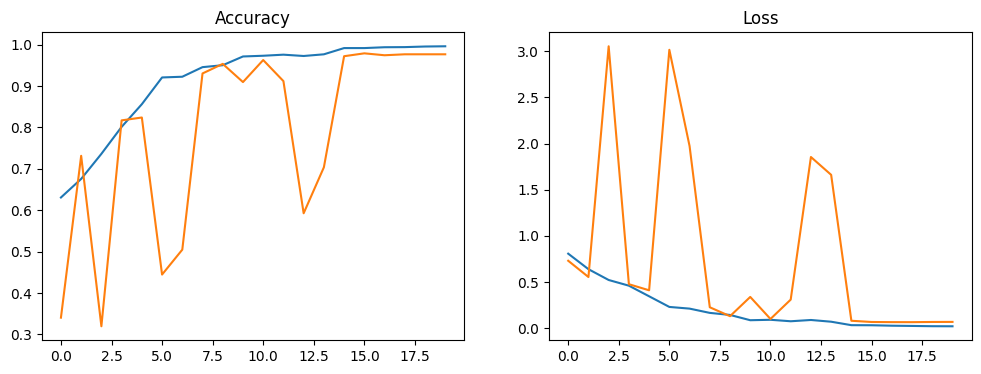

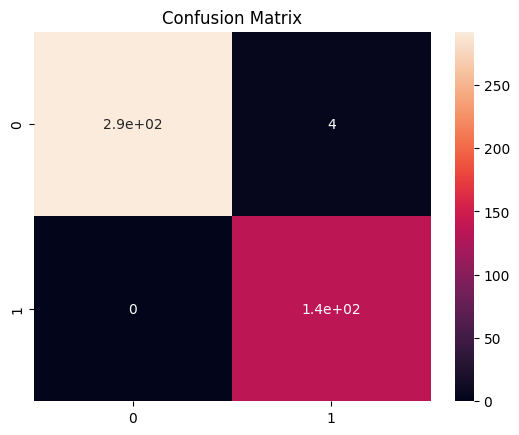

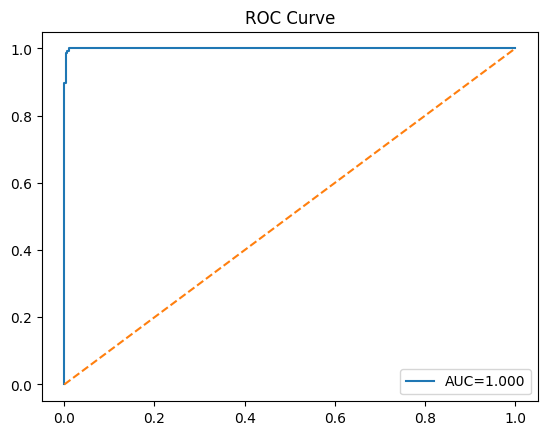

                precision    recall  f1-score   support

Non-Dysarthric       1.00      0.99      0.99       296
    Dysarthric       0.97      1.00      0.99       136

      accuracy                           0.99       432
     macro avg       0.99      0.99      0.99       432
  weighted avg       0.99      0.99      0.99       432



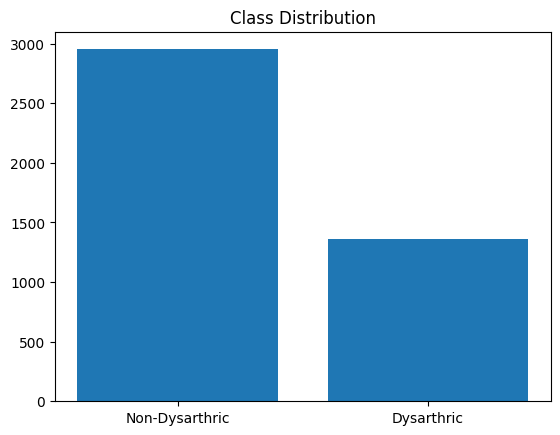

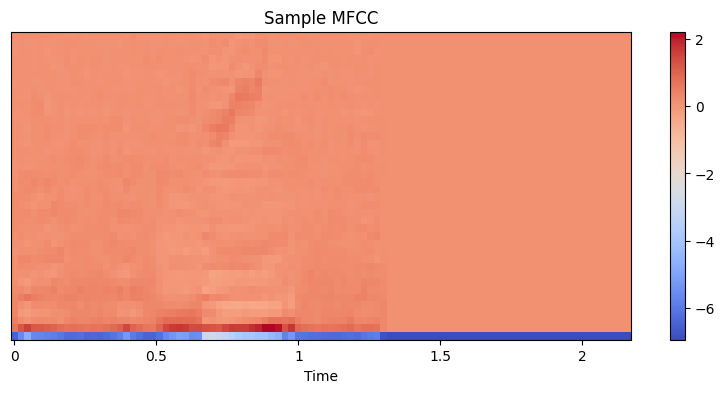

DONE ✅


In [11]:
# ============================================================
# Dysarthria Detection using LSTM — ONE CELL COMPLETE CODE
# ============================================================

# !pip install librosa soundfile tqdm

import zipfile, os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display

from pathlib import Path
from tqdm import tqdm
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# ─── STEP 1: LOAD ZIP ─────────────────────────
zip_files = glob.glob('/content/**/*.zip', recursive=True)
if not zip_files:
    raise FileNotFoundError("Upload dataset ZIP in Colab")

ZIP_PATH = zip_files[0]
EXTRACT_DIR = '/content/dysarthria_dataset'

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

# ─── STEP 2: CONFIG ─────────────────────────
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

SAMPLE_RATE = 16000
DURATION = 3.0
N_MFCC = 40
HOP_LENGTH = 512
N_FFT = 1024

# ─── STEP 3: FEATURE EXTRACTION ─────────────────────────
def extract_mfcc(file):
    try:
        y, _ = librosa.load(str(file), sr=SAMPLE_RATE)
        target_len = int(SAMPLE_RATE * DURATION)

        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        mfcc = librosa.feature.mfcc(y=y, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                                   hop_length=HOP_LENGTH, n_fft=N_FFT)

        mfcc = (mfcc - np.mean(mfcc)) / (np.std(mfcc) + 1e-9)
        return mfcc
    except:
        return None

def collect_files(root, dirs, label):
    data = []
    for d in dirs:
        path = root / d
        for f in path.rglob("*.wav"):
            data.append((f, label))
    return data

records = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS, 1) + \
          collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, 0)

features, labels = [], []

for f, label in tqdm(records):
    mfcc = extract_mfcc(f)
    if mfcc is not None:
        features.append(mfcc)
        labels.append(label)

features = np.array(features)
labels = np.array(labels)

# ─── STEP 4: RESHAPE FOR LSTM ─────────────────────────
features = np.transpose(features, (0, 2, 1))  # (N, TIME, 40)

# ─── STEP 5: SPLIT ─────────────────────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    features, labels, test_size=0.10, stratify=labels, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111, stratify=y_train_val, random_state=42)

print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))

# ─── STEP 6: LSTM MODEL ─────────────────────────
model = keras.Sequential([
    layers.LSTM(128, return_sequences=True, input_shape=X_train.shape[1:]),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.LSTM(64),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(2, activation='softmax')
])

model.summary()

# ─── STEP 7: TRAIN ─────────────────────────
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
cw = {0: cw[0], 1: cw[1]}

model.compile(
    optimizer=keras.optimizers.Adam(5e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_list = [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(patience=3)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=cw,
    callbacks=callbacks_list
)

# ─── STEP 8: EVALUATION ─────────────────────────
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print("Test Accuracy:", acc * 100)

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

class_names = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: GRAPHS ─────────────────────────

# Accuracy & Loss
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")
plt.show()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True)
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob[:,1])
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

# Metrics
print(classification_report(y_test, y_pred, target_names=class_names))

# Class Distribution
cnt = Counter(labels)
plt.bar(class_names, [cnt[0], cnt[1]])
plt.title("Class Distribution")
plt.show()

# Sample MFCC
plt.figure(figsize=(10,4))
librosa.display.specshow(features[0].T, x_axis='time')
plt.title("Sample MFCC")
plt.colorbar()
plt.show()

print("DONE ✅")

TensorFlow: 2.20.0
GPU: []


100%|██████████| 4316/4316 [00:42<00:00, 101.76it/s]


Train: 3450 Val: 432 Test: 432


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 94, 256)        │       173,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 94, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 94, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,330 (1.32 MB)

 Trainable params: 346,562 (1.32 MB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 60s 459ms/step - accuracy: 0.6971 - loss: 0.7109 - val_accuracy: 0.8449 - val_loss: 0.5788 - learning_rate: 3.0000e-04
Epoch 2/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 53s 489ms/step - accuracy: 0.8565 - loss: 0.3617 - val_accuracy: 0.9421 - val_loss: 0.3635 - learning_rate: 3.0000e-04
Epoch 3/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 47s 435ms/step - accuracy: 0.9249 - loss: 0.2189 - val_accuracy: 0.7824 - val_loss: 0.4480 - learning_rate: 3.0000e-04
Epoch 4/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 85s 461ms/step - accuracy: 0.9409 - loss: 0.1674 - val_accuracy: 0.9606 - val_loss: 0.1360 - learning_rate: 3.0000e-04
Epoch 5/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 79s 434ms/step - accuracy: 0.9519 - loss: 0.1325 - val_accuracy: 0.9468 - val_loss: 0.1689 - learning_rate: 3.0000e-04
Epoch 6/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 84s 458ms/step - accuracy: 0.9635 - loss: 0.1037 - val_accuracy: 0.9560 - val_loss: 0.1539 - learning_rate: 3.0000e-04
Epoch 7/25
108/108 ━━━━━━━━━━━━━━━━━━━━ 79s 43

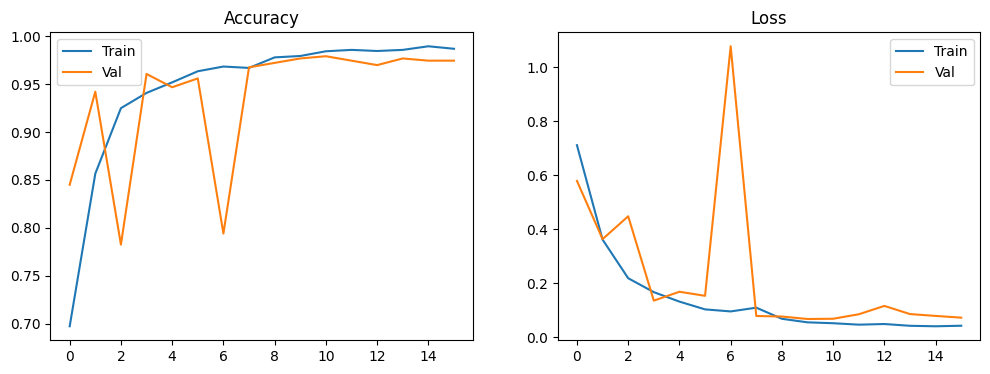

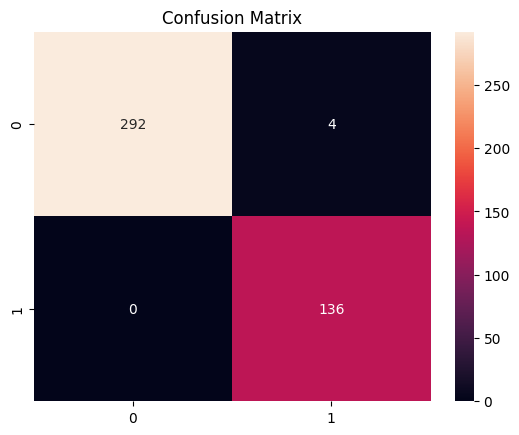

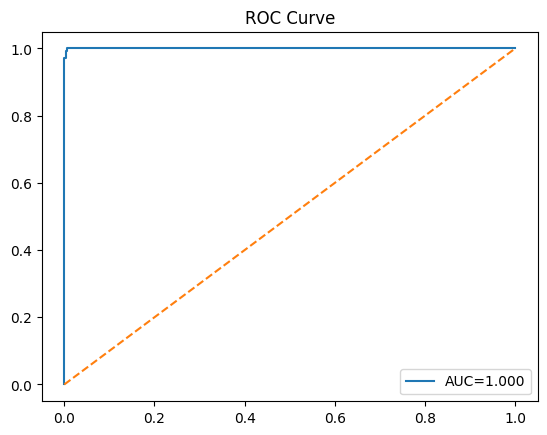


Classification Report:

                precision    recall  f1-score   support

Non-Dysarthric       1.00      0.99      0.99       296
    Dysarthric       0.97      1.00      0.99       136

      accuracy                           0.99       432
     macro avg       0.99      0.99      0.99       432
  weighted avg       0.99      0.99      0.99       432



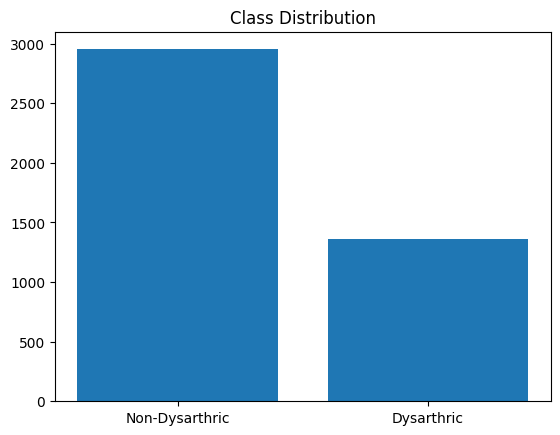

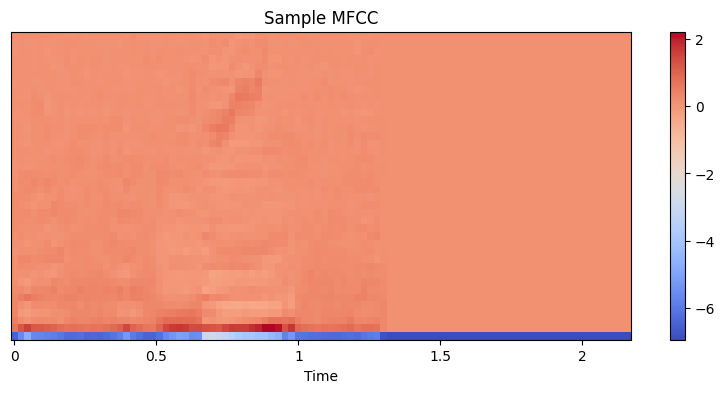


DONE ✅ BiLSTM Model Executed Successfully


In [12]:
# ============================================================
# Dysarthria Detection using BiLSTM — ONE CELL COMPLETE CODE
# ============================================================

# !pip install librosa soundfile tqdm

import zipfile, os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display

from pathlib import Path
from tqdm import tqdm
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# ─── STEP 1: LOAD ZIP ─────────────────────────
zip_files = glob.glob('/content/**/*.zip', recursive=True)
if not zip_files:
    raise FileNotFoundError("Upload dataset ZIP")

ZIP_PATH = zip_files[0]
EXTRACT_DIR = '/content/dysarthria_dataset'

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

# ─── STEP 2: CONFIG ─────────────────────────
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

SAMPLE_RATE = 16000
DURATION = 3.0
N_MFCC = 40
HOP_LENGTH = 512
N_FFT = 1024

# ─── STEP 3: FEATURE EXTRACTION ─────────────────────────
def extract_mfcc(file):
    try:
        y, _ = librosa.load(str(file), sr=SAMPLE_RATE)
        target_len = int(SAMPLE_RATE * DURATION)

        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        mfcc = librosa.feature.mfcc(y=y, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                                   hop_length=HOP_LENGTH, n_fft=N_FFT)

        mfcc = (mfcc - np.mean(mfcc)) / (np.std(mfcc) + 1e-9)
        return mfcc
    except:
        return None

def collect_files(root, dirs, label):
    data = []
    for d in dirs:
        path = root / d
        for f in path.rglob("*.wav"):
            data.append((f, label))
    return data

records = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS, 1) + \
          collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, 0)

features, labels = [], []

for f, label in tqdm(records):
    mfcc = extract_mfcc(f)
    if mfcc is not None:
        features.append(mfcc)
        labels.append(label)

features = np.array(features)
labels = np.array(labels)

# ─── STEP 4: RESHAPE FOR BiLSTM ─────────────────────────
features = np.transpose(features, (0, 2, 1))  # (N, TIME, 40)

# ─── STEP 5: SPLIT ─────────────────────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    features, labels, test_size=0.10, stratify=labels, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111,
    stratify=y_train_val, random_state=42)

print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))

# ─── STEP 6: BiLSTM MODEL ─────────────────────────
model = keras.Sequential([

    layers.Bidirectional(layers.LSTM(128, return_sequences=True),
                         input_shape=X_train.shape[1:]),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Bidirectional(layers.LSTM(64)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(2, activation='softmax')
])

model.summary()

# ─── STEP 7: TRAIN ─────────────────────────
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
cw = {0: cw[0], 1: cw[1]}

model.compile(
    optimizer=keras.optimizers.Adam(3e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_list = [
    callbacks.EarlyStopping(patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(patience=3)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    class_weight=cw,
    callbacks=callbacks_list,
    verbose=1
)

# ─── STEP 8: EVALUATION ─────────────────────────
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {acc*100:.2f}%")

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

class_names = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: GRAPHS ─────────────────────────

# Accuracy & Loss
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.legend(); plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend(); plt.title("Loss")
plt.show()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob[:,1])
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

# Class Distribution
cnt = Counter(labels)
plt.bar(class_names, [cnt[0], cnt[1]])
plt.title("Class Distribution")
plt.show()

# MFCC Visualization
plt.figure(figsize=(10,4))
librosa.display.specshow(features[0].T, x_axis='time')
plt.title("Sample MFCC")
plt.colorbar()
plt.show()

print("\nDONE ✅ BiLSTM Model Executed Successfully")

100%|██████████| 4316/4316 [00:37<00:00, 116.07it/s]


Feature shape: (4314, 3760)
Train: 3450 Val: 432 Test: 432
Validation Accuracy: 94.9074074074074

Test Accuracy: 98.61111111111111


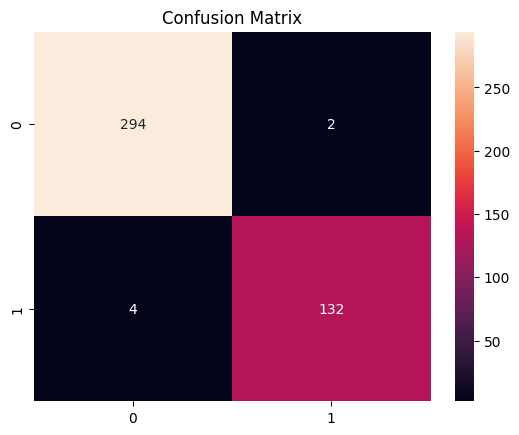

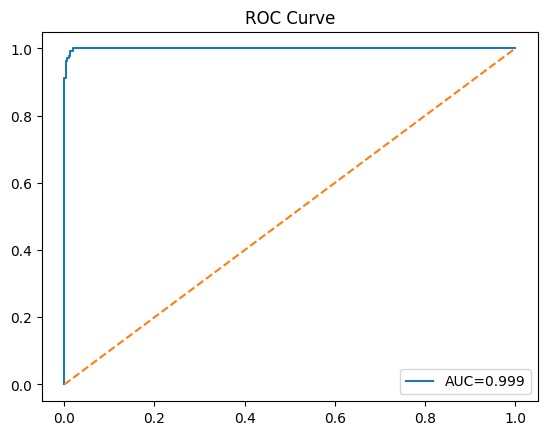


Classification Report:

                precision    recall  f1-score   support

Non-Dysarthric       0.99      0.99      0.99       296
    Dysarthric       0.99      0.97      0.98       136

      accuracy                           0.99       432
     macro avg       0.99      0.98      0.98       432
  weighted avg       0.99      0.99      0.99       432



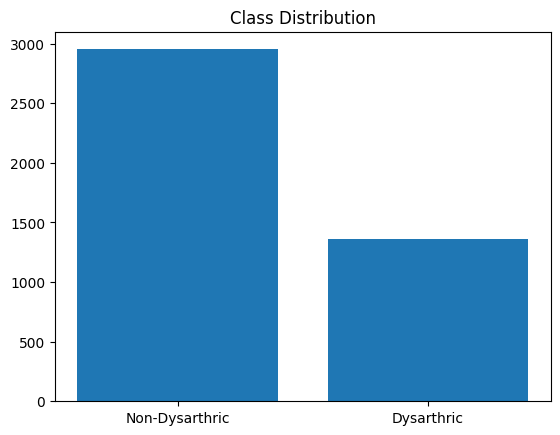

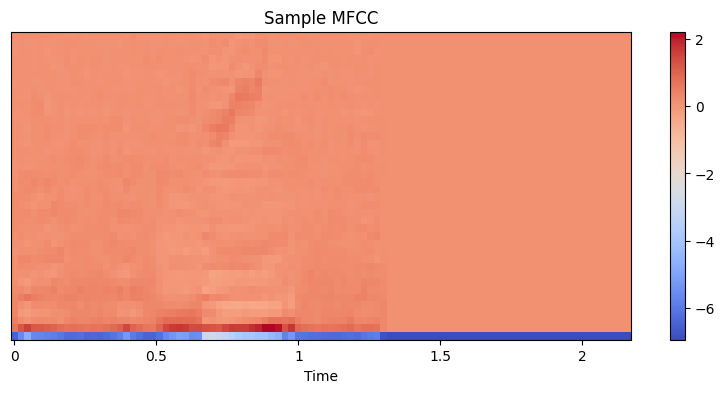


DONE ✅ SVM Model Executed Successfully


In [13]:
# ============================================================
# Dysarthria Detection using SVM — ONE CELL COMPLETE CODE
# ============================================================

# !pip install librosa soundfile tqdm

import zipfile, os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display

from pathlib import Path
from tqdm import tqdm
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# ─── STEP 1: LOAD ZIP ─────────────────────────
zip_files = glob.glob('/content/**/*.zip', recursive=True)
if not zip_files:
    raise FileNotFoundError("Upload dataset ZIP")

ZIP_PATH = zip_files[0]
EXTRACT_DIR = '/content/dysarthria_dataset'

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

# ─── STEP 2: CONFIG ─────────────────────────
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

SAMPLE_RATE = 16000
DURATION = 3.0
N_MFCC = 40
HOP_LENGTH = 512
N_FFT = 1024

# ─── STEP 3: FEATURE EXTRACTION ─────────────────────────
def extract_mfcc(file):
    try:
        y, _ = librosa.load(str(file), sr=SAMPLE_RATE)
        target_len = int(SAMPLE_RATE * DURATION)

        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        mfcc = librosa.feature.mfcc(y=y, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                                   hop_length=HOP_LENGTH, n_fft=N_FFT)

        mfcc = (mfcc - np.mean(mfcc)) / (np.std(mfcc) + 1e-9)

        return mfcc.flatten()   # 🔥 Flatten for SVM

    except:
        return None

def collect_files(root, dirs, label):
    data = []
    for d in dirs:
        path = root / d
        for f in path.rglob("*.wav"):
            data.append((f, label))
    return data

records = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS, 1) + \
          collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, 0)

features, labels = [], []

for f, label in tqdm(records):
    mfcc = extract_mfcc(f)
    if mfcc is not None:
        features.append(mfcc)
        labels.append(label)

X = np.array(features)
y = np.array(labels)

print("Feature shape:", X.shape)

# ─── STEP 4: SPLIT ─────────────────────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111,
    stratify=y_train_val, random_state=42)

print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))

# ─── STEP 5: SCALING ─────────────────────────
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# ─── STEP 6: SVM MODEL ─────────────────────────
model = SVC(kernel='rbf', probability=True, C=10, gamma='scale')

model.fit(X_train, y_train)

# ─── STEP 7: VALIDATION (Optional Monitoring) ─────────────────
val_acc = model.score(X_val, y_val)
print("Validation Accuracy:", val_acc * 100)

# ─── STEP 8: TEST EVALUATION ─────────────────────────
test_acc = model.score(X_test, y_test)
print("\nTest Accuracy:", test_acc * 100)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

class_names = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: GRAPHS ─────────────────────────

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob[:,1])
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

# Class Distribution
cnt = Counter(y)
plt.bar(class_names, [cnt[0], cnt[1]])
plt.title("Class Distribution")
plt.show()

# Sample MFCC Visualization
mfcc_sample = X[0].reshape(N_MFCC, -1)

plt.figure(figsize=(10,4))
librosa.display.specshow(mfcc_sample, x_axis='time')
plt.title("Sample MFCC")
plt.colorbar()
plt.show()

print("\nDONE ✅ SVM Model Executed Successfully")

100%|██████████| 4316/4316 [00:37<00:00, 113.86it/s]


Feature shape: (4314, 3760)
Train: 3450 Val: 432 Test: 432
Validation Accuracy: 81.94444444444444

Test Accuracy: 84.02777777777779


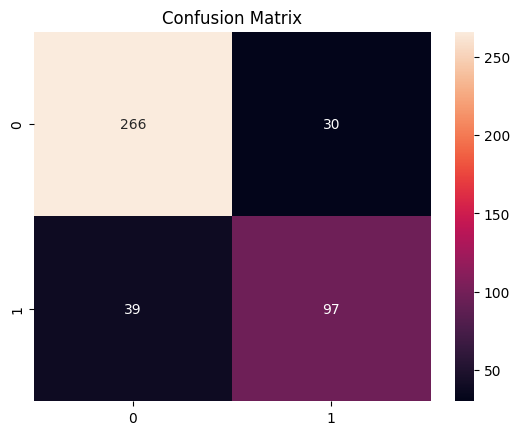

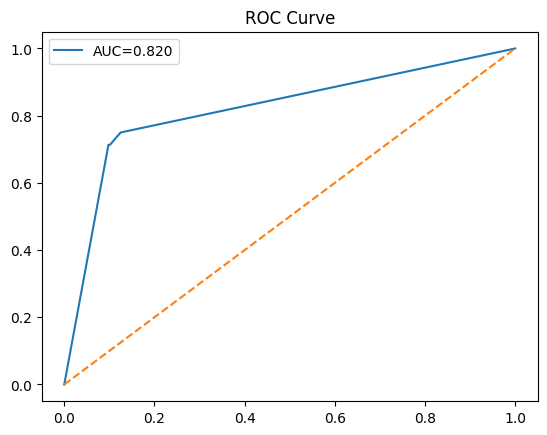


Classification Report:

                precision    recall  f1-score   support

Non-Dysarthric       0.87      0.90      0.89       296
    Dysarthric       0.76      0.71      0.74       136

      accuracy                           0.84       432
     macro avg       0.82      0.81      0.81       432
  weighted avg       0.84      0.84      0.84       432



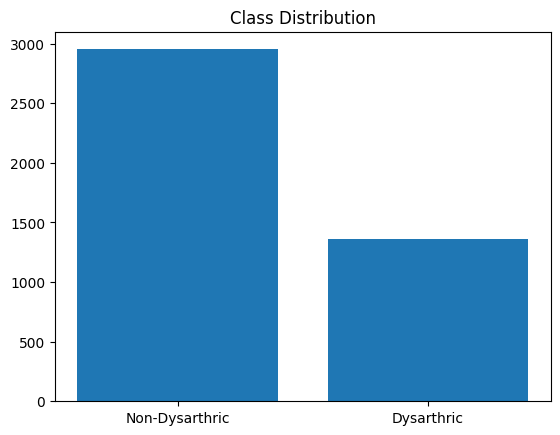

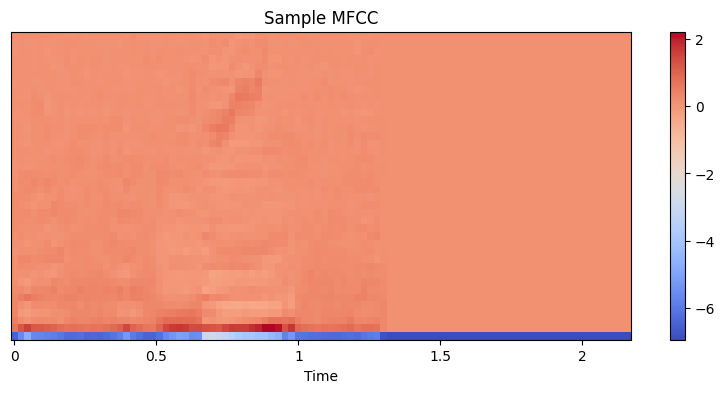


DONE ✅ Decision Tree Model Executed Successfully


In [14]:
# ============================================================
# Dysarthria Detection using Decision Tree — ONE CELL CODE
# ============================================================

# !pip install librosa soundfile tqdm

import zipfile, os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display

from pathlib import Path
from tqdm import tqdm
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# ─── STEP 1: LOAD ZIP ─────────────────────────
zip_files = glob.glob('/content/**/*.zip', recursive=True)
if not zip_files:
    raise FileNotFoundError("Upload dataset ZIP")

ZIP_PATH = zip_files[0]
EXTRACT_DIR = '/content/dysarthria_dataset'

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

# ─── STEP 2: CONFIG ─────────────────────────
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

SAMPLE_RATE = 16000
DURATION = 3.0
N_MFCC = 40
HOP_LENGTH = 512
N_FFT = 1024

# ─── STEP 3: FEATURE EXTRACTION ─────────────────────────
def extract_mfcc(file):
    try:
        y, _ = librosa.load(str(file), sr=SAMPLE_RATE)
        target_len = int(SAMPLE_RATE * DURATION)

        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        mfcc = librosa.feature.mfcc(y=y, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                                   hop_length=HOP_LENGTH, n_fft=N_FFT)

        mfcc = (mfcc - np.mean(mfcc)) / (np.std(mfcc) + 1e-9)

        return mfcc.flatten()   # Flatten for ML model

    except:
        return None

def collect_files(root, dirs, label):
    data = []
    for d in dirs:
        path = root / d
        for f in path.rglob("*.wav"):
            data.append((f, label))
    return data

records = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS, 1) + \
          collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, 0)

features, labels = [], []

for f, label in tqdm(records):
    mfcc = extract_mfcc(f)
    if mfcc is not None:
        features.append(mfcc)
        labels.append(label)

X = np.array(features)
y = np.array(labels)

print("Feature shape:", X.shape)

# ─── STEP 4: SPLIT ─────────────────────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111,
    stratify=y_train_val, random_state=42)

print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))

# ─── STEP 5: SCALING ─────────────────────────
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# ─── STEP 6: DECISION TREE MODEL ─────────────────────────
model = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

model.fit(X_train, y_train)

# ─── STEP 7: VALIDATION ─────────────────────────
val_acc = model.score(X_val, y_val)
print("Validation Accuracy:", val_acc * 100)

# ─── STEP 8: TEST EVALUATION ─────────────────────────
test_acc = model.score(X_test, y_test)
print("\nTest Accuracy:", test_acc * 100)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

class_names = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: GRAPHS ─────────────────────────

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob[:,1])
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

# Class Distribution
cnt = Counter(y)
plt.bar(class_names, [cnt[0], cnt[1]])
plt.title("Class Distribution")
plt.show()

# Sample MFCC Visualization
mfcc_sample = X[0].reshape(N_MFCC, -1)

plt.figure(figsize=(10,4))
librosa.display.specshow(mfcc_sample, x_axis='time')
plt.title("Sample MFCC")
plt.colorbar()
plt.show()

print("\nDONE ✅ Decision Tree Model Executed Successfully")

100%|██████████| 4316/4316 [00:40<00:00, 106.79it/s]


Feature shape: (4314, 3760)
Train: 3450 Val: 432 Test: 432
Validation Accuracy: 90.74074074074075

Test Accuracy: 91.66666666666666


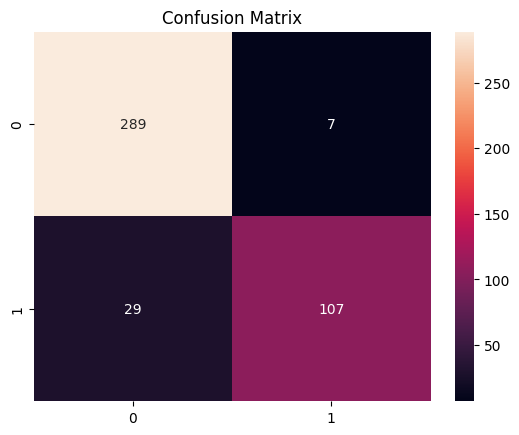

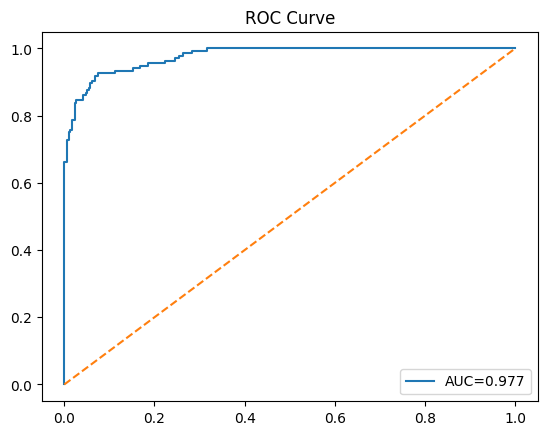


Classification Report:

                precision    recall  f1-score   support

Non-Dysarthric       0.91      0.98      0.94       296
    Dysarthric       0.94      0.79      0.86       136

      accuracy                           0.92       432
     macro avg       0.92      0.88      0.90       432
  weighted avg       0.92      0.92      0.91       432



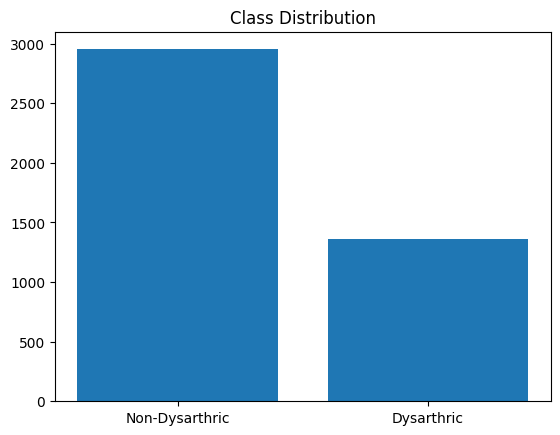

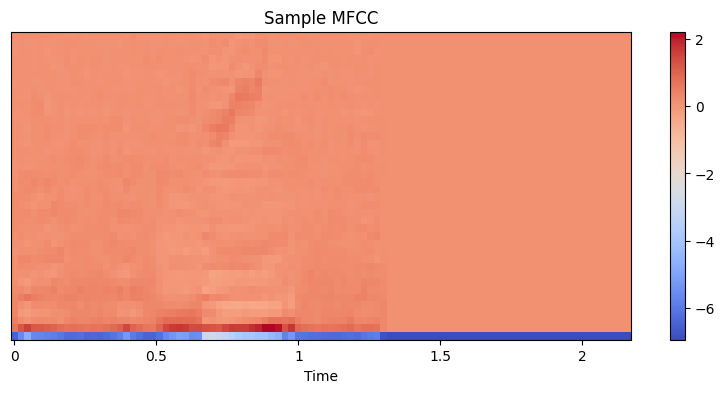


DONE ✅ Random Forest Model Executed Successfully


In [15]:
# ============================================================
# Dysarthria Detection using Random Forest — ONE CELL CODE
# ============================================================

# !pip install librosa soundfile tqdm

import zipfile, os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display

from pathlib import Path
from tqdm import tqdm
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# ─── STEP 1: LOAD ZIP ─────────────────────────
zip_files = glob.glob('/content/**/*.zip', recursive=True)
if not zip_files:
    raise FileNotFoundError("Upload dataset ZIP")

ZIP_PATH = zip_files[0]
EXTRACT_DIR = '/content/dysarthria_dataset'

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

# ─── STEP 2: CONFIG ─────────────────────────
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

SAMPLE_RATE = 16000
DURATION = 3.0
N_MFCC = 40
HOP_LENGTH = 512
N_FFT = 1024

# ─── STEP 3: FEATURE EXTRACTION ─────────────────────────
def extract_mfcc(file):
    try:
        y, _ = librosa.load(str(file), sr=SAMPLE_RATE)
        target_len = int(SAMPLE_RATE * DURATION)

        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        mfcc = librosa.feature.mfcc(y=y, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                                   hop_length=HOP_LENGTH, n_fft=N_FFT)

        mfcc = (mfcc - np.mean(mfcc)) / (np.std(mfcc) + 1e-9)

        return mfcc.flatten()   # Flatten for ML model

    except:
        return None

def collect_files(root, dirs, label):
    data = []
    for d in dirs:
        path = root / d
        for f in path.rglob("*.wav"):
            data.append((f, label))
    return data

records = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS, 1) + \
          collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, 0)

features, labels = [], []

for f, label in tqdm(records):
    mfcc = extract_mfcc(f)
    if mfcc is not None:
        features.append(mfcc)
        labels.append(label)

X = np.array(features)
y = np.array(labels)

print("Feature shape:", X.shape)

# ─── STEP 4: SPLIT ─────────────────────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111,
    stratify=y_train_val, random_state=42)

print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))

# ─── STEP 5: SCALING ─────────────────────────
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# ─── STEP 6: RANDOM FOREST MODEL ─────────────────────────
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# ─── STEP 7: VALIDATION ─────────────────────────
val_acc = model.score(X_val, y_val)
print("Validation Accuracy:", val_acc * 100)

# ─── STEP 8: TEST EVALUATION ─────────────────────────
test_acc = model.score(X_test, y_test)
print("\nTest Accuracy:", test_acc * 100)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

class_names = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: GRAPHS ─────────────────────────

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob[:,1])
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

# Class Distribution
cnt = Counter(y)
plt.bar(class_names, [cnt[0], cnt[1]])
plt.title("Class Distribution")
plt.show()

# Sample MFCC Visualization
mfcc_sample = X[0].reshape(N_MFCC, -1)

plt.figure(figsize=(10,4))
librosa.display.specshow(mfcc_sample, x_axis='time')
plt.title("Sample MFCC")
plt.colorbar()
plt.show()

print("\nDONE ✅ Random Forest Model Executed Successfully")

100%|██████████| 4316/4316 [00:41<00:00, 103.76it/s]


Feature shape: (4314, 3760)
Train: 3450 Val: 432 Test: 432
Validation Accuracy: 62.03703703703704

Test Accuracy: 62.731481481481474


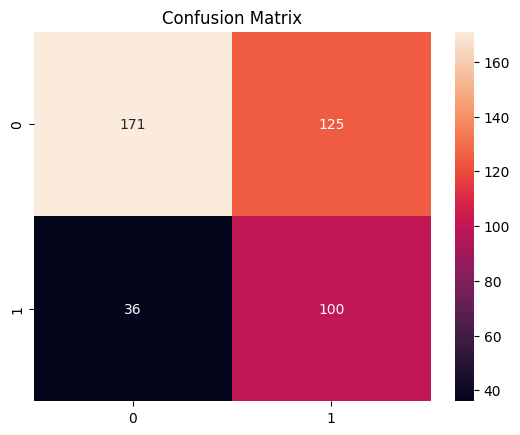

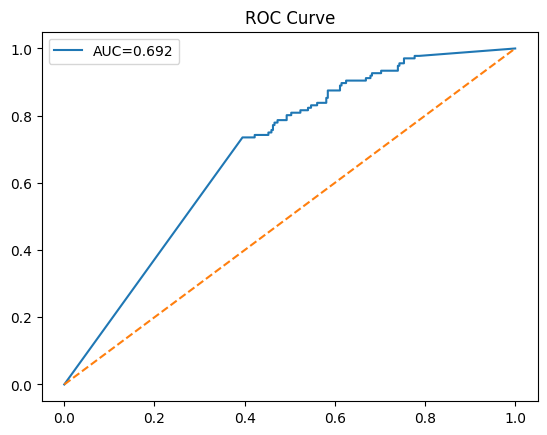


Classification Report:

                precision    recall  f1-score   support

Non-Dysarthric       0.83      0.58      0.68       296
    Dysarthric       0.44      0.74      0.55       136

      accuracy                           0.63       432
     macro avg       0.64      0.66      0.62       432
  weighted avg       0.71      0.63      0.64       432



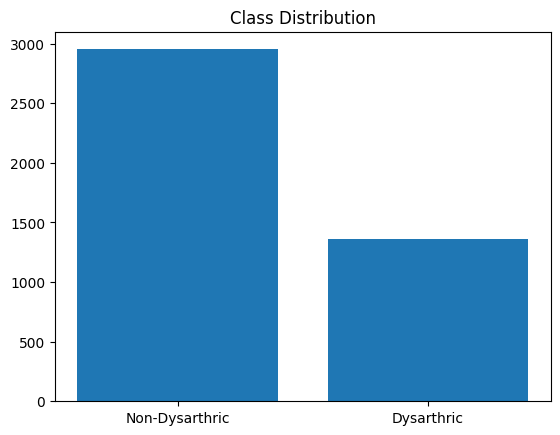

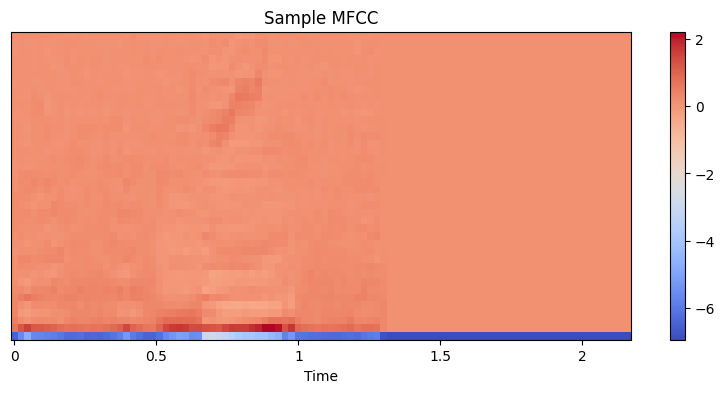


DONE ✅ Naive Bayes Model Executed Successfully


In [16]:
# ============================================================
# Dysarthria Detection using Naive Bayes — ONE CELL CODE
# ============================================================

# !pip install librosa soundfile tqdm

import zipfile, os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display

from pathlib import Path
from tqdm import tqdm
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# ─── STEP 1: LOAD ZIP ─────────────────────────
zip_files = glob.glob('/content/**/*.zip', recursive=True)
if not zip_files:
    raise FileNotFoundError("Upload dataset ZIP")

ZIP_PATH = zip_files[0]
EXTRACT_DIR = '/content/dysarthria_dataset'

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

# ─── STEP 2: CONFIG ─────────────────────────
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

SAMPLE_RATE = 16000
DURATION = 3.0
N_MFCC = 40
HOP_LENGTH = 512
N_FFT = 1024

# ─── STEP 3: FEATURE EXTRACTION ─────────────────────────
def extract_mfcc(file):
    try:
        y, _ = librosa.load(str(file), sr=SAMPLE_RATE)
        target_len = int(SAMPLE_RATE * DURATION)

        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        mfcc = librosa.feature.mfcc(y=y, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                                   hop_length=HOP_LENGTH, n_fft=N_FFT)

        mfcc = (mfcc - np.mean(mfcc)) / (np.std(mfcc) + 1e-9)

        return mfcc.flatten()   # Flatten for NB

    except:
        return None

def collect_files(root, dirs, label):
    data = []
    for d in dirs:
        path = root / d
        for f in path.rglob("*.wav"):
            data.append((f, label))
    return data

records = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS, 1) + \
          collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, 0)

features, labels = [], []

for f, label in tqdm(records):
    mfcc = extract_mfcc(f)
    if mfcc is not None:
        features.append(mfcc)
        labels.append(label)

X = np.array(features)
y = np.array(labels)

print("Feature shape:", X.shape)

# ─── STEP 4: SPLIT ─────────────────────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111,
    stratify=y_train_val, random_state=42)

print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))

# ─── STEP 5: SCALING ─────────────────────────
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# ─── STEP 6: NAIVE BAYES MODEL ─────────────────────────
model = GaussianNB()

model.fit(X_train, y_train)

# ─── STEP 7: VALIDATION ─────────────────────────
val_acc = model.score(X_val, y_val)
print("Validation Accuracy:", val_acc * 100)

# ─── STEP 8: TEST EVALUATION ─────────────────────────
test_acc = model.score(X_test, y_test)
print("\nTest Accuracy:", test_acc * 100)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

class_names = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: GRAPHS ─────────────────────────

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob[:,1])
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

# Class Distribution
cnt = Counter(y)
plt.bar(class_names, [cnt[0], cnt[1]])
plt.title("Class Distribution")
plt.show()

# Sample MFCC Visualization
mfcc_sample = X[0].reshape(N_MFCC, -1)

plt.figure(figsize=(10,4))
librosa.display.specshow(mfcc_sample, x_axis='time')
plt.title("Sample MFCC")
plt.colorbar()
plt.show()

print("\nDONE ✅ Naive Bayes Model Executed Successfully")

100%|██████████| 4316/4316 [01:07<00:00, 64.00it/s]


Feature shape: (4314, 240)
After PCA shape: (3450, 120)

Validation Accuracy: 68.98%
Test Accuracy: 72.45%


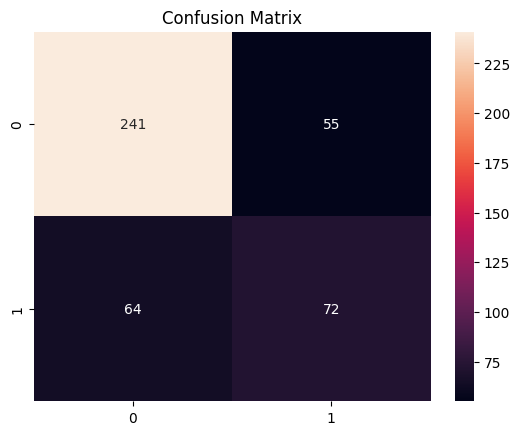

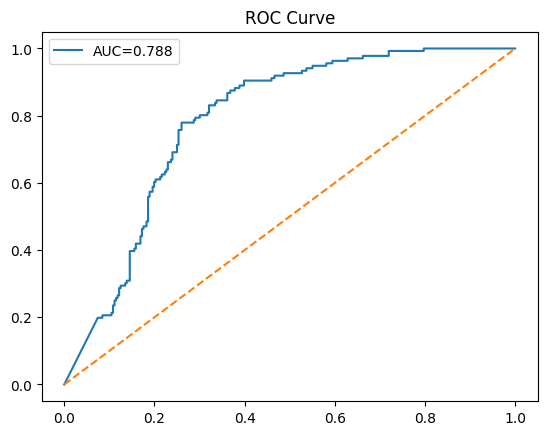


Classification Report:

                precision    recall  f1-score   support

Non-Dysarthric       0.79      0.81      0.80       296
    Dysarthric       0.57      0.53      0.55       136

      accuracy                           0.72       432
     macro avg       0.68      0.67      0.67       432
  weighted avg       0.72      0.72      0.72       432



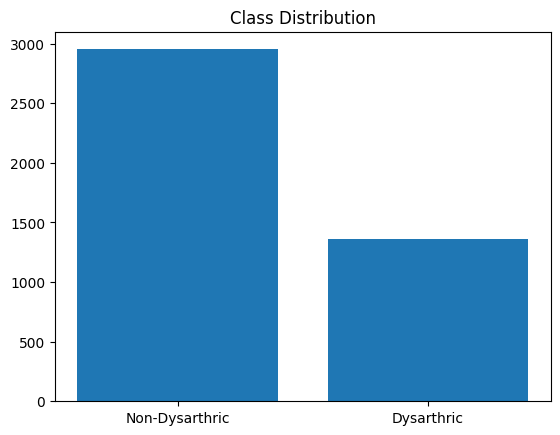


DONE ✅ Improved Naive Bayes


In [17]:
# ============================================================
# Improved Naive Bayes for Dysarthria Detection — ONE CELL
# ============================================================

# !pip install librosa soundfile tqdm

import zipfile, os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa

from pathlib import Path
from tqdm import tqdm
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

np.random.seed(42)

# ─── STEP 1: LOAD ZIP ─────────────────────────
zip_files = glob.glob('/content/**/*.zip', recursive=True)
if not zip_files:
    raise FileNotFoundError("Upload dataset ZIP")

ZIP_PATH = zip_files[0]
EXTRACT_DIR = '/content/dysarthria_dataset'

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

# ─── STEP 2: CONFIG ─────────────────────────
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

SAMPLE_RATE = 16000
DURATION = 3.0
N_MFCC = 40

# ─── STEP 3: IMPROVED FEATURE EXTRACTION ─────────────────────────
def extract_features(file):
    try:
        y, _ = librosa.load(str(file), sr=SAMPLE_RATE)
        target_len = int(SAMPLE_RATE * DURATION)

        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        # MFCC
        mfcc = librosa.feature.mfcc(y=y, sr=SAMPLE_RATE, n_mfcc=N_MFCC)

        # Delta features
        delta = librosa.feature.delta(mfcc)
        delta2 = librosa.feature.delta(mfcc, order=2)

        # Combine features
        feat = np.vstack([mfcc, delta, delta2])

        # 🔥 Statistical aggregation (VERY IMPORTANT)
        feat_mean = np.mean(feat, axis=1)
        feat_std  = np.std(feat, axis=1)

        return np.hstack([feat_mean, feat_std])  # Final feature vector

    except:
        return None

def collect_files(root, dirs, label):
    data = []
    for d in dirs:
        path = root / d
        for f in path.rglob("*.wav"):
            data.append((f, label))
    return data

records = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS, 1) + \
          collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, 0)

X, y = [], []

for f, label in tqdm(records):
    feat = extract_features(f)
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)
y = np.array(y)

print("Feature shape:", X.shape)

# ─── STEP 4: SPLIT ─────────────────────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111,
    stratify=y_train_val, random_state=42)

# ─── STEP 5: SCALING ─────────────────────────
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# ─── STEP 6: PCA (KEY IMPROVEMENT) ─────────────────────────
pca = PCA(n_components=0.95)  # keep 95% variance
X_train = pca.fit_transform(X_train)
X_val   = pca.transform(X_val)
X_test  = pca.transform(X_test)

print("After PCA shape:", X_train.shape)

# ─── STEP 7: NAIVE BAYES ─────────────────────────
model = GaussianNB(var_smoothing=1e-8)

model.fit(X_train, y_train)

# ─── STEP 8: EVALUATION ─────────────────────────
val_acc = model.score(X_val, y_val)
test_acc = model.score(X_test, y_test)

print(f"\nValidation Accuracy: {val_acc*100:.2f}%")
print(f"Test Accuracy: {test_acc*100:.2f}%")

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

class_names = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: GRAPHS ─────────────────────────

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob[:,1])
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

# Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

# Class Distribution
cnt = Counter(y)
plt.bar(class_names, [cnt[0], cnt[1]])
plt.title("Class Distribution")
plt.show()

print("\nDONE ✅ Improved Naive Bayes")

100%|██████████| 4316/4316 [01:03<00:00, 67.71it/s]


Feature shape: (4314, 240)
After PCA shape: (3450, 120)

Validation Accuracy: 89.81%
Test Accuracy: 93.06%


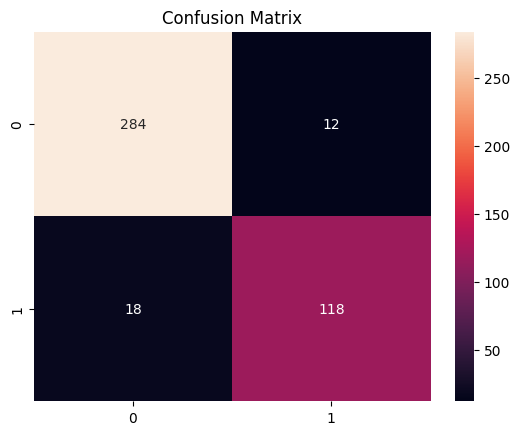

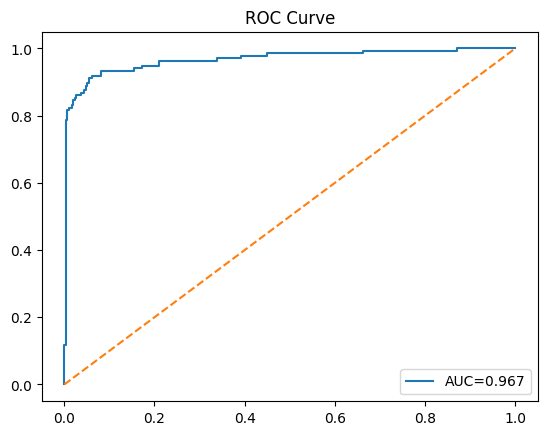


Classification Report:

                precision    recall  f1-score   support

Non-Dysarthric       0.94      0.96      0.95       296
    Dysarthric       0.91      0.87      0.89       136

      accuracy                           0.93       432
     macro avg       0.92      0.91      0.92       432
  weighted avg       0.93      0.93      0.93       432



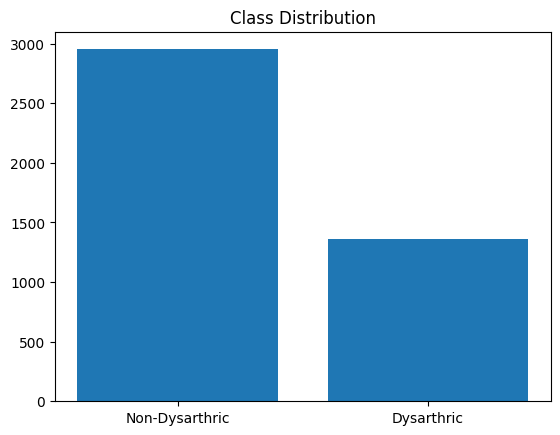


DONE ✅ Logistic Regression Model


In [18]:
# ============================================================
# Dysarthria Detection using Logistic Regression — ONE CELL
# ============================================================

# !pip install librosa soundfile tqdm

import zipfile, os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa

from pathlib import Path
from tqdm import tqdm
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

np.random.seed(42)

# ─── STEP 1: LOAD ZIP ─────────────────────────
zip_files = glob.glob('/content/**/*.zip', recursive=True)
if not zip_files:
    raise FileNotFoundError("Upload dataset ZIP")

ZIP_PATH = zip_files[0]
EXTRACT_DIR = '/content/dysarthria_dataset'

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

# ─── STEP 2: CONFIG ─────────────────────────
DATASET_ROOT = Path(EXTRACT_DIR) / 'Dysarthria and Non Dysarthria' / 'Dataset'

DYSARTHRIC_DIRS     = ['Female_dysarthria', 'Male_Dysarthria']
NON_DYSARTHRIC_DIRS = ['Female_Non_Dysarthria', 'Male_Non_Dysarthria']

SAMPLE_RATE = 16000
DURATION = 3.0
N_MFCC = 40

# ─── STEP 3: FEATURE EXTRACTION (IMPROVED) ─────────────────────────
def extract_features(file):
    try:
        y, _ = librosa.load(str(file), sr=SAMPLE_RATE)
        target_len = int(SAMPLE_RATE * DURATION)

        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        # MFCC
        mfcc = librosa.feature.mfcc(y=y, sr=SAMPLE_RATE, n_mfcc=N_MFCC)

        # Delta features
        delta = librosa.feature.delta(mfcc)
        delta2 = librosa.feature.delta(mfcc, order=2)

        # Combine
        feat = np.vstack([mfcc, delta, delta2])

        # Statistical aggregation
        feat_mean = np.mean(feat, axis=1)
        feat_std  = np.std(feat, axis=1)

        return np.hstack([feat_mean, feat_std])

    except:
        return None

def collect_files(root, dirs, label):
    data = []
    for d in dirs:
        path = root / d
        for f in path.rglob("*.wav"):
            data.append((f, label))
    return data

records = collect_files(DATASET_ROOT, DYSARTHRIC_DIRS, 1) + \
          collect_files(DATASET_ROOT, NON_DYSARTHRIC_DIRS, 0)

X, y = [], []

for f, label in tqdm(records):
    feat = extract_features(f)
    if feat is not None:
        X.append(feat)
        y.append(label)

X = np.array(X)
y = np.array(y)

print("Feature shape:", X.shape)

# ─── STEP 4: SPLIT ─────────────────────────
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111,
    stratify=y_train_val, random_state=42)

# ─── STEP 5: SCALING ─────────────────────────
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# ─── STEP 6: PCA ─────────────────────────
pca = PCA(n_components=0.95)
X_train = pca.fit_transform(X_train)
X_val   = pca.transform(X_val)
X_test  = pca.transform(X_test)

print("After PCA shape:", X_train.shape)

# ─── STEP 7: LOGISTIC REGRESSION MODEL ─────────────────────────
model = LogisticRegression(
    max_iter=1000,
    C=2.0,
    solver='lbfgs'
)

model.fit(X_train, y_train)

# ─── STEP 8: EVALUATION ─────────────────────────
val_acc = model.score(X_val, y_val)
test_acc = model.score(X_test, y_test)

print(f"\nValidation Accuracy: {val_acc*100:.2f}%")
print(f"Test Accuracy: {test_acc*100:.2f}%")

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

class_names = ['Non-Dysarthric', 'Dysarthric']

# ─── STEP 9: GRAPHS ─────────────────────────

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob[:,1])
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

# Class Distribution
cnt = Counter(y)
plt.bar(class_names, [cnt[0], cnt[1]])
plt.title("Class Distribution")
plt.show()

print("\nDONE ✅ Logistic Regression Model")